# [이론] 글로벌 모델 — 지하철 100개 역을 신경망 하나로

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 오늘 배울 것

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 딥러닝 시계열</div>
<h1 style="color:#000000;margin:10px 0">글로벌 모델 — 지하철 100개 역을 신경망 하나로</h1>
<div style="font-size:1.05em;color:#656565">100개 역의 하루 승차를 신경망 하나로 학습하고, 직전 7일 평균·계절 나이브와 역 단위 MASE 로 비교합니다</div>
</div>

본문은 필수이고, 접힌 상자(「자세히」·「더 깊이」)는 선택입니다.

## 0. 오늘 배울 것

**100개 역을 한 모델로 학습한 신경망을 다음 주 역별 인력 예측에 쓸까요?**

역 운영은 혼잡에 대응할 인력을 역마다 두는 일입니다. 지금 역 운영팀은 바로 전 7일의 평균 승차를 다음 7일 모두에 적어 인력을 정합니다. 이 규칙을 **직전 7일 평균**이라 부릅니다. 강남이면 6월 17～23일 평균 81,105명을 6월 24～30일 7일 모두의 기준으로 둡니다.

시계열 과목은 서울 공유자전거 한 계열을 시간 단위로 예측했습니다. 여러 계열을 모델 하나로 학습하는 글로벌 모델을 다루려면 계열이 여럿이어야 합니다. 그래서 자료를 서울 지하철 100개 역(2024년까지 하루 평균 승차가 가장 많은 역 100곳)의 하루 승차로 바꿉니다.

역마다 승차 규모가 5배 가까이 달라, RMSE 를 평균하면 큰 역의 오차가 점수를 좌우합니다. 그래서 대표 지표를 **역 단위 MASE** 로 바꿉니다. 역마다 MASE 를 구해 100개 역에서 평균한 값입니다.

- **출처**: 서울열린데이터광장 「서울시 지하철 호선별 역별 승하차 인원 정보」(OA-12914, 공공누리 제1유형)
- **기간·단위**: 2015-01-01～2026-06-30 의 4,199일, 하루 승차·하차 인원(명)

원자료는 2,480,294행입니다. 한 행은 한 호선·역의 하루 기록이고, 열은 날짜 `date`·호선 `line`·역 `station`·승차 `board`·하차 `alight` 입니다.

| `date` | `line` | `station` | `board` | `alight` |
|---|---|---|---:|---:|
| 2016-10-17 | 2호선 | 잠실 | 81660 | 75743 |
| 2026-06-23 | 2호선 | 강남 | 94098 | 91592 |
| 2026-06-23 | 2호선 | 잠실(송파구청) | 84590 | 83272 |
| 2026-06-23 | 8호선 | 잠실(송파구청) | 20555 | 23664 |

- **정제**: 역 이름 뒤의 괄호 별칭을 뗍니다. 2호선 잠실은 2016-10-18 부터 「잠실(송파구청)」으로 적혀 있어, 떼어야 4,199일이 한 역으로 이어집니다. 9호선 2～3단계 구간의 두 호선 표기도 하나로 맞춥니다. 같은 날짜·호선·역이 두 번 적힌 370건은 더해 한 행으로 합치므로, 370행이 줄어 2,479,924행이 됩니다.
- **역**: 4,190일 이상 기록된 역 521개 가운데 2024년 말까지 평균 승차가 가장 큰 100개 역입니다. 같은 이름이라도 호선이 다르면 다른 역으로 보고(위 표의 2호선 잠실과 8호선 잠실), 강남은 2호선 강남 하나입니다.
- **빈칸**: 고른 100개 역은 4,199일이 하루도 빠짐없이 기록되어 있습니다. 100개 역 × 4,199일 = 419,900개 값에 빈칸도, 채운 값도 없습니다.

여러 역의 날짜별 승차를 한 표에 모은 이 자료를 **100개 역 표**라 부릅니다. 한 행은 하루, 한 열은 역 하나라 4,199행 × 100열이고, 값은 승차 인원(명)입니다. 열은 2024년까지 평균 승차가 큰 차례입니다. 아래는 앞 5개 열과 94번째 열인 경부선 구로입니다.

| 날짜 | 2호선 강남 | 2호선 잠실 | 2호선 홍대입구 | 2호선 신림 | 2호선 구로디지털단지 | ⋯ | 경부선 구로 |
|---|---:|---:|---:|---:|---:|:---:|---:|
| 2015-01-01(목, 신정) | 39173 | 43883 | 57469 | 39099 | 25089 | ⋯ | 11215 |
| ⋮ | ⋮ | ⋮ | ⋮ | ⋮ | ⋮ | | ⋮ |
| 2026-06-22(월) | 90946 | 80141 | 76105 | 58810 | 63993 | ⋯ | 18338 |
| 2026-06-23(화) | 94098 | 84590 | 74099 | 60047 | 65247 | ⋯ | 18718 |
| ⋮ | ⋮ | ⋮ | ⋮ | ⋮ | ⋮ | | ⋮ |

2026-06-23 행의 강남·잠실 값이 위 원자료 두 행의 `board` 이고, 하차 `alight` 는 쓰지 않습니다.

원자료의 `line` 은 1호선 가운데 서울역～청량리 구간만 「1호선」으로 적습니다. 나머지 구간은 경부선·경인선·경원선 같은 철도 노선 이름으로 적습니다. 그래서 경부선 구로는 1호선 구로역이고, 2호선 구로디지털단지와 다른 역입니다.

뒤에서는 2호선 잠실과 경부선 구로를 자주 견줍니다. 2026-06-23 까지 1년 평균 승차는 잠실이 80,499명으로 가장 크고, 구로가 16,594명으로 가장 작습니다. 이 1년만 보면 첫 열 강남(77,858명)보다 잠실이 큽니다. 열 순서는 2024년까지 평균으로 매겨 강남이 첫 열입니다.

<details class="lms-extra"><summary>더 깊이 — 자료를 고른 규칙</summary>

- **개념**: 계열 하나는 (호선, 역) 한 쌍의 날짜별 승차입니다. 원자료 2,480,294행에서 계열 639개가 나옵니다.
- **직관**: 11년 반을 모두 쓰려면 첫날과 마지막 날에 기록이 있고 빠진 날이 거의 없는 계열만 남겨야 합니다.
- **예**: 2015-01-01 과 2026-06-30 에 기록이 있고, 4,199일 가운데 4,190일 이상 기록된 계열이 521개입니다. 이 521개 안에서 2024-12-31 까지의 평균 승차가 큰 100개를 고릅니다.
- **왜 쓰나**: 역을 고른 기준일 2024-12-31 이 모든 예측 원점보다 앞이라, 채점할 7일의 승차가 역을 고르는 데 쓰이지 않습니다.
- **특징**: 조건만으로는 빈칸이 없다고 보장되지 않아, 고른 100개 역에 빈칸이 없는지 따로 확인했습니다(0개). 호선이 다르면 다른 역으로 봅니다.

</details>

같은 채점 규칙으로 모델마다 MASE 를 적어 나가는 표를 **평가표**라 부릅니다.

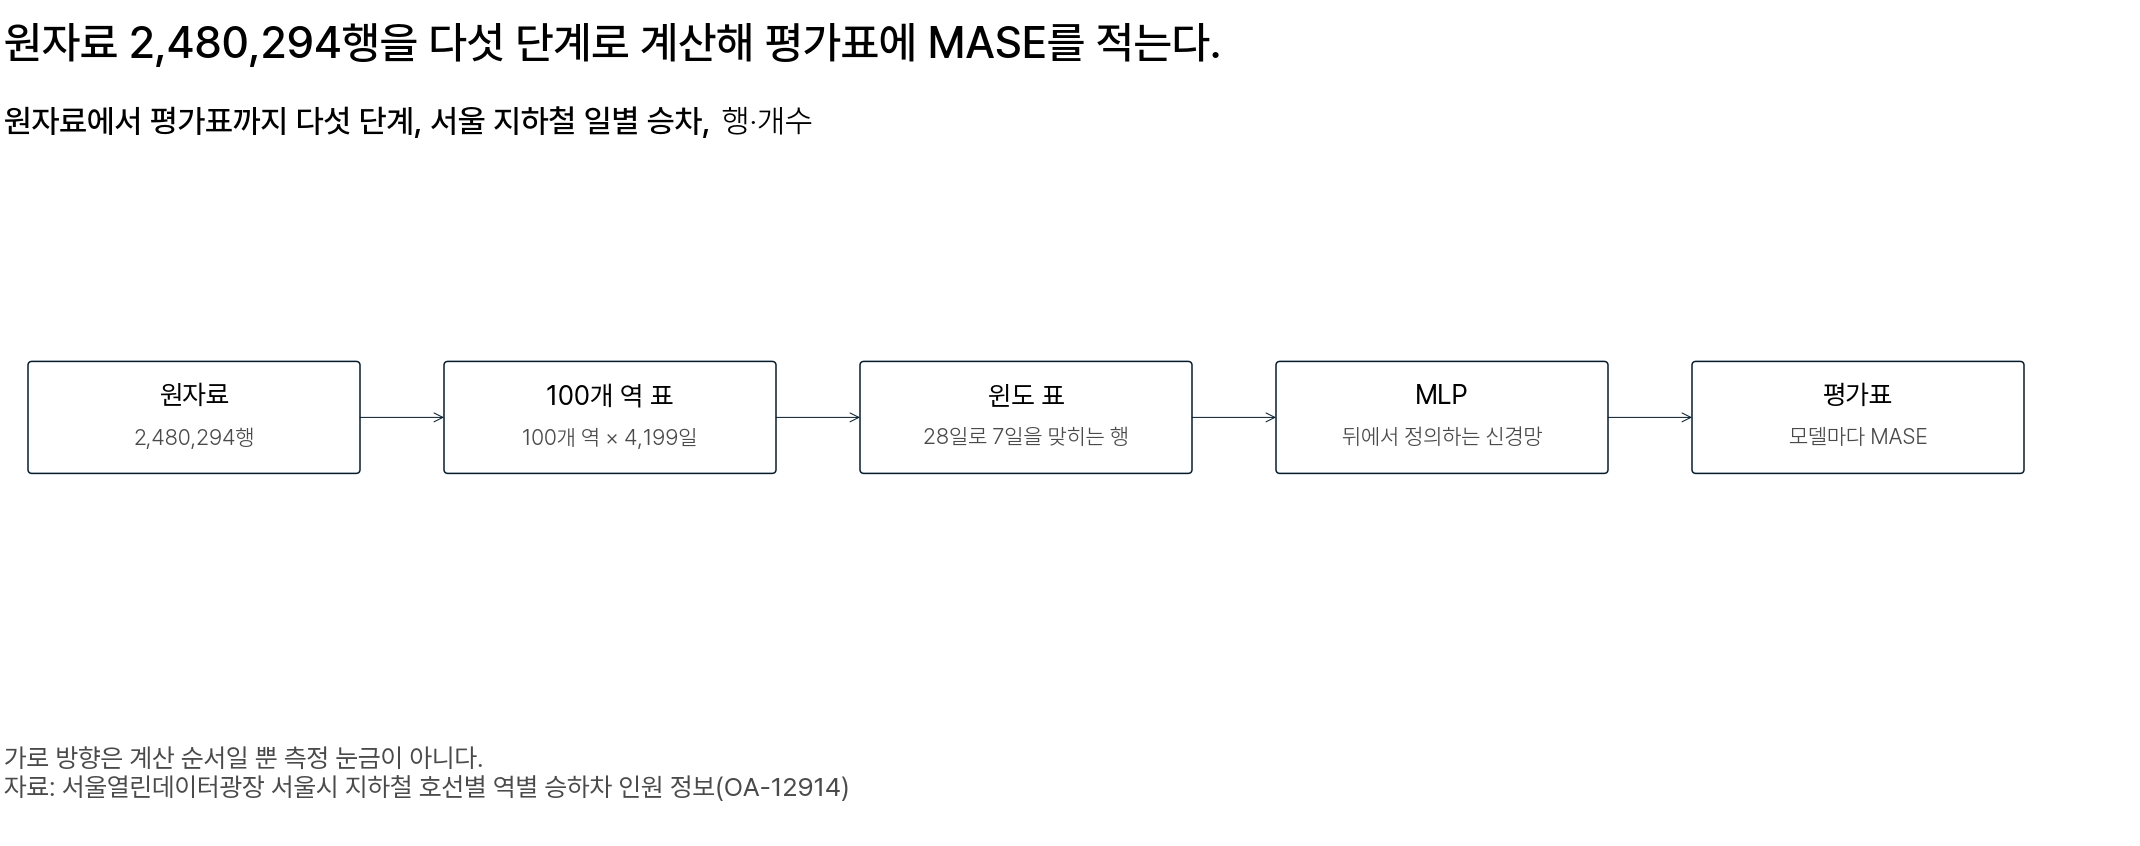

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 원자료에서 평가표까지의 차례. 원자료 2,480,294행을 100개 역 표로 모은다. 28일로 다음 7일을 맞히는 행(윈도 표)으로 잘라 뒤에서 정의하는 신경망 MLP(다층 퍼셉트론, multilayer perceptron)에 넣고, 낸 예측의 MASE 를 평가표에 적는다</em></p>

<div class="lms-summary">

**정리**

새 예측이 바꿀 대상은 역 운영팀이 지금 쓰는 직전 7일 평균입니다. 역마다 규모가 5배 가까이 달라, 대표 지표는 역 단위 MASE 로 둡니다.

**할 일**

- 100개 역 × 4,199일 = 419,900개 값의 100개 역 표 하나로 모든 모델을 만듭니다
- 모델마다 역 단위 MASE 로 채점해 평가표에 적습니다

모든 모델을 같은 100개 역 표와 같은 지표로 채점해야 평가표에서 모델끼리 견줄 수 있습니다.

</div>

## 1. 예측 원점과 역 단위 MASE

새 모델과 지금 쓰는 직전 7일 평균을 어떤 규칙으로 채점해 견줄까요?

### 예측 원점 [필수]

시계열 과목에서 **예측 원점(forecast origin)** 은 학습 구간의 마지막 시각이었습니다. 서울 공유자전거에서는 11월 16일 23시였습니다. 딥러닝 시계열은 원점을 예측하는 7일의 첫날로 잡습니다. 원점 2025-12-10 이면 이렇습니다.

| 날짜 | 시계열 과목의 원점(학습 구간의 마지막 날) | 딥러닝 시계열의 원점(채점 첫날) |
|---|---|---|
| 12월 9일(화) | 원점, 학습 구간의 마지막 날 | 원점 전날, 예측에 쓰는 마지막 날 |
| 12월 10일(수) | 채점 첫날 | 원점, 채점 첫날 |
| 12월 16일(화) | 채점 마지막 날 | 채점 마지막 날 |

쓰는 자료와 채점하는 7일은 같고, 원점이라 부르는 날만 하루 뒤로 옮겼습니다.

예측 원점은 수요일 다섯 개(2025-08-13 · 10-01 · 12-10 · 2026-02-11 · 06-24)입니다. 원점 다섯 개에서 100개 역 × 7일 × 5 = 3,500개 값을 채점합니다.

<img src="https://otexts.com/fpp3/fpp_files/figure-html/cv1-1.png" width="640" height="300"/>
<p align="center"><em>▲ 예측 원점을 옮겨 가며 채점하는 시계열 교차 검증(time series cross-validation). 한 행이 한 분할(split)이고, 파란 점이 학습에 쓴 관측, 주황 점이 그 분할에서 채점하는 시각, 회색 점이 아직 쓰지 않은 미래다. 아래 행일수록 원점이 늦고 학습 구간이 길다 (출처: fpp3 §5.10)</em></p>

시계열 과목에서 본 그림입니다. 이 과목에서는 주황 점이 원점부터 이어지는 7일이고, 행이 다섯입니다.

출처의 fpp3 는 시계열 예측 교재 『Forecasting: Principles and Practice』 3판의 약칭입니다. § 뒤 수는 그 교재의 목차 번호입니다.

<details class="lms-extra"><summary>더 깊이 — 원자료가 공개되는 시차와 예측 원점 전날까지 안다는 가정</summary>

원자료는 매일 3일 전 자료까지 공개되므로, 실제 운영이라면 예측 원점 2026-06-24 에 6월 21일까지만 압니다. 딥러닝 시계열은 6월 23일까지 안다고 가정했고, 그만큼 실제 운영보다 유리한 조건입니다.

</details>

**예측 원점은 채점 첫날이고, 모델은 원점마다 원점 전날까지의 자료로 새로 학습합니다.**

### 베이스라인 둘: 계절 나이브와 직전 7일 평균 [필수]

**베이스라인(baseline)** 은 학습 없이 과거 승차를 옮겨 적는 예측 규칙입니다. 평가표에는 **계절 나이브(seasonal naive)** 와 직전 7일 평균 둘을 적습니다.

계절 나이브는 1주일 전 같은 요일 값을 옮겨 적습니다. 한 역의 계절 나이브 예측은 다음과 같습니다.

$$
\hat y_{o+h} = y_{o+h-7}, \qquad h = 0, 1, \dots, 6
$$

- $o$: 예측 원점
- $h$: 원점에서 며칠 뒤인지(0～6)
- $\hat y_{o+h}$: 원점 $h$일 뒤의 예측 승차 인원(명)
- $y_{o+h-7}$: 1주일 전 같은 요일의 실제 승차 인원(명)

$h = 6$ 이어도 원점 전날 값 $y_{o-1}$ 까지만 씁니다.

원점 전날 값을 7일 내내 옮겨 적는 **나이브 기법(naive method)** 도 있습니다. 이 방식은 주말에도 원점 전날의 평일 승차를 그대로 적습니다.

**평가표의 베이스라인은 계절 나이브와 직전 7일 평균이고, 요일 차이를 놓치는 나이브 기법은 뺍니다.**

### 역 단위 MASE: 계절 나이브가 평소 빗나가던 크기의 몇 배인가 [필수]

**평균 절대 스케일 오차(mean absolute scaled error, MASE)** 는 시계열 과목에서 배운 지표입니다. 시계열 과목의 식은 다음과 같습니다.

$$
\text{MASE} = \frac{\text{MAE}}{Q}
$$

- $\text{MAE}$: 채점 구간에서 모델의 평균 절대 오차
- $Q$: 학습 구간에서 계절 나이브의 평균 절대 오차

계절 나이브는 주기 $m$ 만큼 앞의 값을 예측으로 씁니다. 서울 공유자전거는 시간 단위라 $m = 24$ 였고, 서울 지하철은 하루 단위라 $m = 7$ 입니다.

서울 지하철에서는 이 식을 역마다 씁니다. 역 $i$ 의 MASE 는 다음과 같습니다.

$$
\text{MASE}_i = \frac{\text{MAE}_i}{Q_i}
$$

- $i$: 역 번호(1～100)

분자는 채점 7일에 모델이 그 역에서 빗나간 크기의 평균입니다.

$$
\text{MAE}_i = \frac{1}{7}\sum_{h=0}^{6} |y_{i,o+h} - \hat y_{i,o+h}|
$$

- $y_{i,o+h}$: 역 $i$ 의 원점 $h$일 뒤 실제 승차 인원(명)
- $\hat y_{i,o+h}$: 같은 날 모델의 예측 승차 인원(명)

분모는 원점 전날까지 계절 나이브가 그 역에서 빗나간 크기의 평균입니다.

$$
Q_i = \frac{1}{n}\sum_{t} |y_{i,t} - y_{i,t-7}|
$$

- $t$: 1주일 전 값이 있는 2015-01-08 부터 원점 전날까지의 날
- $n$: 그런 날의 수
- $|y_{i,t} - y_{i,t-7}|$: 그날 계절 나이브의 절대 오차(명)

100개 역의 $\text{MASE}_i$ 를 평균한 값이 역 단위 MASE 입니다.

$$
\text{역 단위 MASE} = \frac{1}{100}\sum_{i=1}^{100} \text{MASE}_i = \frac{1}{100}\sum_{i=1}^{100} \frac{\text{MAE}_i}{Q_i}
$$

실습 코드에서는 $Q_i$ 를 `qden` 이라 부릅니다.

역 단위 MASE 의 계산 구조는 이렇습니다.

$$
\textbf{역마다 모델 오차} \div \textbf{계절 나이브가 평소 빗나가던 크기} \;\longrightarrow\; \textbf{100개 역 평균}
$$

역 단위 MASE 는 다음 질문에 답합니다.

> 이 모델은 역마다 계절 나이브가 평소 빗나가던 크기의 몇 배를 빗나갔고, 100개 역에서 평균하면 몇 배인가?

| MASE 값 | 뜻 |
|---|---|
| 1 | 계절 나이브가 원점 전날까지 그 역에서 평소 빗나가던 만큼 빗나감 |
| 1 보다 작음 | 평소보다 덜 빗나감 |
| 1 보다 큼 | 평소보다 더 빗나감 |
| 0.5 | 평소의 절반만큼 빗나감 |

원점 2026-06-24 의 $Q_i$ 는 2호선 잠실 6,405.5명, 경부선 구로 1,380.8명입니다. 7일 내내 1,000명씩 빗나가면 잠실의 MASE 는 1,000 ÷ 6,405.5 = 0.156 입니다. 같은 오차가 구로에서는 1,000 ÷ 1,380.8 = 0.724 입니다.

그래서 같은 1,000명이라도 구로의 MASE 가 잠실의 4.6배입니다.

잠실에서 MASE 가 0.5 라면 하루 평균 6,405.5 × 0.5 ≈ 3,203명 빗나갔다는 뜻입니다.

새 모델이 낫다고 말하려면 1 이 아니라 같은 원점의 계절 나이브 MASE 와 견줍니다. 계절 나이브 자신도 1 이 아닌 MASE 를 받기 때문입니다. 공휴일이 없는 원점 2025-12-10 의 7일에는 0.419 입니다.

그날이나 1주일 전이 공휴일인 날은 1주일 전 값이 크게 빗나가 $Q_i$ 를 키웁니다. 그래서 공휴일이 없는 7일에는 계절 나이브의 오차가 $Q_i$ 보다 작습니다.

<details class="lms-extra"><summary>자세히 — 공휴일 없는 주에 계절 나이브의 MASE 가 1 보다 작은 까닭</summary>

$Q_i$ 는 2015년부터 날마다 구한 $|y_{i,t} - y_{i,t-7}|$ 의 평균입니다. 그런 날의 수를 $N$, 그 차이의 합을 $S$ 라 두면 다음과 같습니다.

$$
Q_i = \frac{S}{N}
$$

원점 2025-12-10 이면 $N$ 일의 9.4% 가 그날이나 1주일 전이 공휴일인 날입니다. 이 비율은 달력으로 정해져 100개 역에서 같습니다. 이 날들이 $S$ 에서 차지하는 비율은 역마다 조금 다르고, 100개 역을 모두 더하면 51.3% 입니다.

여기서는 100개 역을 더한 비율 51.3% 를 모든 역에 쓰는 근사로 셈합니다. 나머지 날은 날 수로 $1 - 0.094 = 0.906$ 이라 $0.906\,N$ 일이고, 차이의 합으로 $1 - 0.513 = 0.487$ 이라 $0.487\,S$ 입니다. 그래서 나머지 날만의 평균은 다음과 같습니다.

$$
\text{나머지 날 평균} = \frac{0.487\,S}{0.906\,N}
$$

이 평균을 $Q_i = S / N$ 으로 나눕니다.

$$
\frac{\text{나머지 날 평균}}{Q_i} = \frac{0.487\,S \,/\, (0.906\,N)}{S \,/\, N}
$$

분자와 분모에 함께 있는 $S$ 와 $N$ 을 약분하고 나눗셈을 계산합니다.

$$
\frac{0.487\,S \,/\, (0.906\,N)}{S \,/\, N} = \frac{0.487}{0.906} \approx 0.54
$$

공휴일 없는 주의 7일은 모두 나머지 날입니다. 원점 2025-12-10 의 7일에는 계절 나이브가 나머지 날 평균보다도 덜 빗나갔습니다. 역마다 $\text{MAE}_i$ 를 나머지 날 평균으로 나누면 100개 역 평균 0.776 입니다.

$\text{MASE}_i$ 의 분자와 분모에 같은 나머지 날 평균을 곱하고 나누면, 두 비율의 곱으로 적을 수 있습니다.

$$
\text{MASE}_i = \frac{\text{MAE}_i}{Q_i} = \frac{\text{MAE}_i}{\text{나머지 날 평균}} \times \frac{\text{나머지 날 평균}}{Q_i}
$$

두 비율을 대입하면 0.776 × 0.54 ≈ 0.42 로, 본문의 0.419 와 맞습니다.

</details>

- **좋은 점**: 규모가 다른 역을 같은 무게로 봅니다.
- **약한 점**: 몇 명 빗나갔는지는 $Q_i$ 를 곱해야 보입니다.
- **이럴 때 쓴다**: 서울 지하철 평가표처럼 규모가 다른 계열을 고르게 보고 모델끼리 견줄 때 씁니다.

역 운영팀은 역마다 인력을 두므로 오차도 역마다 구합니다. A 역을 20명 많게, B 역을 20명 적게 예측하면 두 역을 더한 승차의 오차는 0명입니다. 그래도 A 역은 인력이 남고 B 역은 모자랍니다.

<details class="lms-extra"><summary>더 깊이 — 100개 역 승차를 더한 계열 하나로 채점하면 지워지는 오차</summary>

원점 2025-12-10 의 계절 나이브로 확인해 봅니다. 100개 역 승차를 날마다 더한 계열 하나로 채점하면, 7일 오차 크기의 합이 역마다 구한 합의 0.666배입니다.

1 − 0.666 = 0.334, 곧 오차의 3분의 1이 역끼리 반대로 빗나가 더하는 동안 지워집니다.

</details>

<div class="lms-summary">

**정리**

역 단위 MASE 는 역마다 모델의 MAE 를 그 역의 $Q_i$ 로 나눠 100개 역에서 평균합니다.

**할 일**

- 오차와 $Q_i$ 는 100개 역을 더하지 않고 역마다 구합니다
- $Q_i$ 는 원점 전날까지의 자료로만 만듭니다

오차를 역마다 구해야 반대로 빗나간 역끼리 오차가 지워지지 않습니다.

</div>

### 채점 7일에 평일 공휴일이 있는 주와 없는 주 [필수]

원점 5개는 채점 7일에 평일 공휴일이 있는지에 따라 두 묶음으로 나눕니다. 원점 5개의 채점 7일은 아래 달력과 같습니다.

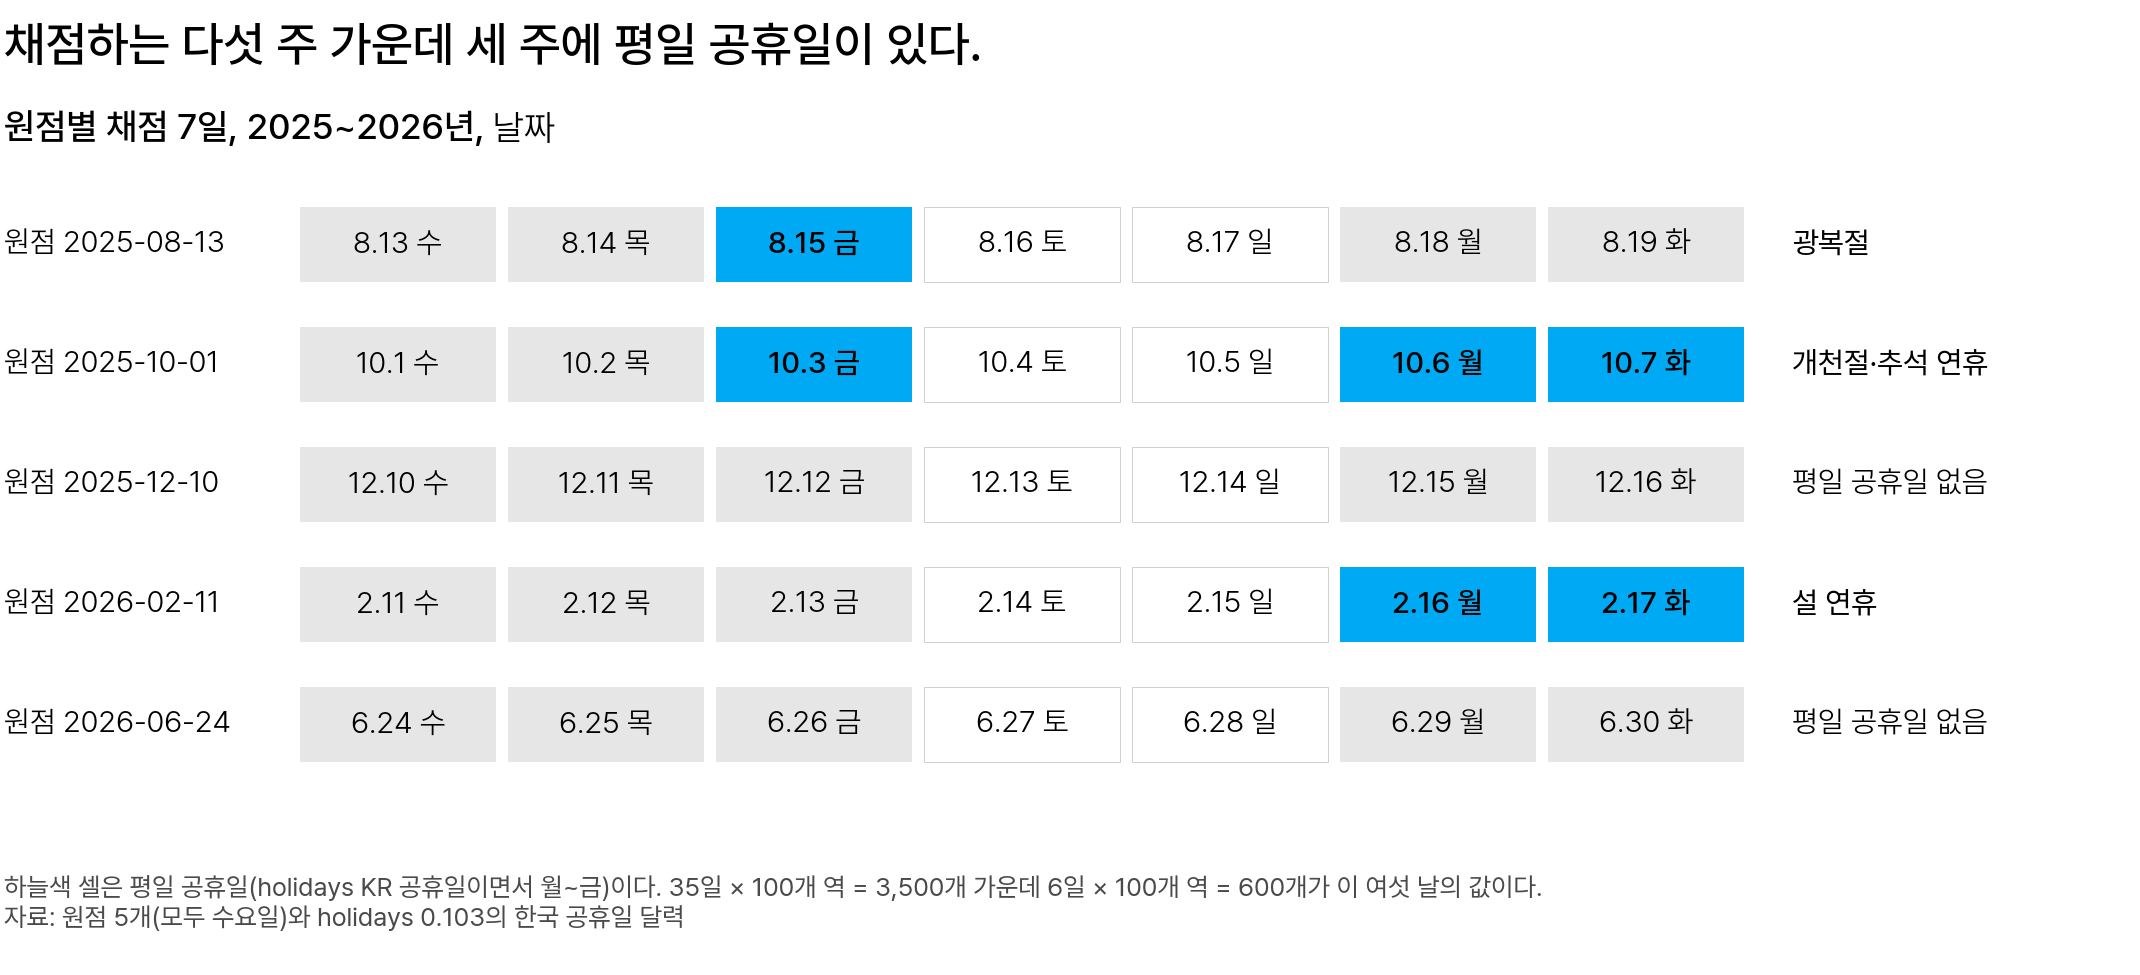

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 채점하는 다섯 주. 한 행이 원점 하나의 채점 7일(수～화)이고, 회색 셀은 평일, 흰 셀은 주말, 하늘색 셀은 평일 공휴일이다. 오른쪽 글자는 그 주의 공휴일 이름이다. 공휴일은 파이썬 라이브러리 holidays 0.103 버전의 한국 공휴일 달력을 따른다</em></p>

공휴일이면서 월～금인 날을 **평일 공휴일**이라 부릅니다. 원점마다 채점 7일은 수요일부터 화요일까지 한 주입니다. 채점하는 다섯 주(35일)를 모두 세면 평일 공휴일은 여섯 날입니다.

| 원점 | 채점 7일 안의 평일 공휴일 | 평일 공휴일 수 |
|---|---|---:|
| 2025-08-13 | 8월 15일 금(광복절) | 1 |
| 2025-10-01 | 10월 3일 금(개천절) · 6일 월(추석) · 7일 화(추석 다음 날) | 3 |
| 2025-12-10 | 없음 | 0 |
| 2026-02-11 | 2월 16일 월(설 전날) · 17일 화(설날) | 2 |
| 2026-06-24 | 없음 | 0 |

원점 순서대로 더하면 1 + 3 + 0 + 2 + 0 = 6일입니다. 이 여섯 날의 값은 6일 × 100개 역 = 600개이고, 채점하는 값 35일 × 100개 역 = 3,500개의 17% 입니다.

평일 공휴일에는 승차가 주말처럼 줄어 1주일 전 같은 요일 값이 크게 빗나갑니다. 다섯 주를 한꺼번에 평균하면 공휴일 없는 주의 오차가 따로 보이지 않습니다. 그래서 원점 5개를 두 묶음으로 나눠 평균합니다.

- **공휴일 없는 두 주**: 원점 2025-12-10 · 2026-06-24
- **공휴일 있는 세 주**: 원점 2025-08-13 · 2025-10-01 · 2026-02-11

| 베이스라인 | 원점 5개 평균 | 공휴일 없는 두 주 | 공휴일 있는 세 주 |
|---|---:|---:|---:|
| 계절 나이브 | 1.838 | 0.445 | 2.767 |
| 직전 7일 평균 | 2.984 | 1.935 | 3.684 |

공휴일 없는 두 주의 0.445 는 원점 2025-12-10 의 0.419 와 2026-06-24 의 0.471 의 평균입니다. 원점 5개 평균은 다섯 주를 한꺼번에 평균한 값이라, 계절 나이브는 (2 × 0.445 + 3 × 2.767) ÷ 5 = 1.838 입니다.

직전 7일 평균은 두 묶음 모두에서 계절 나이브보다 크게 빗나갑니다. 요일과 상관없이 7일에 같은 값을 적기 때문입니다. 강남이면 일요일 6월 28일에도 81,105명을 적지만, 실제는 40,248명입니다. 계절 나이브는 1주일 전 같은 요일 값을 옮겨 이 요일 차이를 맞춥니다.

학습 없이 계절 나이브로 바꾸기만 해도 이만큼 덜 빗나가므로, 신경망은 계절 나이브보다 덜 빗나가야 쓸 까닭이 있습니다.

공휴일 없는 주를 먼저 보는 것은 운영하는 주 대부분이 그런 주이기 때문입니다. 2015년부터 2026년 6월 23일까지 수요일에 시작하는 7일의 80%(598개 가운데 481개)에 평일 공휴일이 없습니다.

<div class="lms-summary">

**정리**

역 단위 MASE 는 공휴일 없는 두 주와 공휴일 있는 세 주로 나눠 읽습니다. 계절 나이브는 두 묶음에서 0.445 와 2.767 입니다.

**할 일**

- 평가표에는 원점 5개 평균도 함께 적고, 모델은 두 묶음 평균으로 고릅니다

새 모델을 쓰려면 먼저 공휴일 없는 두 주에서 계절 나이브(0.445)보다 MASE 가 낮아야 합니다.

</div>

## 2. 윈도 표

계열 하나를 신경망이 받는 표로 어떻게 바꿀까요?

### 윈도 한 행 [필수]

신경망은 필수 머신러닝의 지도학습처럼 입력 열 X 와 정답 열 y 로 된 표를 받습니다. 승차 계열에서 연속한 입력 28일과 그 뒤 출력 7일을 잘라 낸 구간이 **윈도(window)** 이고, 윈도를 한 행씩 모은 표가 **윈도 표**입니다.

윈도 표 한 행의 구조는 이렇습니다.

$$
\textbf{연속한 28일(입력)} \;\longrightarrow\; \textbf{그 뒤 7일(출력)}
$$

윈도 표의 한 행은 다음 질문에 답합니다.

> 연속한 28일의 승차가 이랬을 때, 그 뒤 7일의 승차는 얼마였나?

기호로 적으면 윈도 $j$ 는 다음과 같습니다.

$$
\text{윈도 } j:\quad \underbrace{(y_j,\ \dots,\ y_{j+27})}_{\text{입력 28일}} \;\longrightarrow\; \underbrace{(y_{j+28},\ \dots,\ y_{j+34})}_{\text{출력 7일}}
$$

- $y_j$: 계열의 $j$ 번째 날 승차 인원(명)
- $j$: 윈도 첫날의 번호(윈도를 하루 옮기면 1 커짐)

<img src="https://skforecast.org/latest/img/transform_timeseries.gif" width="640" height="164"/>
<p align="center"><em>▲ 길이 10 계열(왼쪽)을 입력 5개·출력 1개 윈도로 하루씩 옮기며 자르는 과정. 가운데 표의 한 행이 입력 5개이고, 오른쪽 빨간 수가 그 행의 정답이다 (출처: skforecast, Introduction to forecasting)</em></p>

표를 짧게 보려고 강남역의 2026년 6월 17일(수)～23일(화) 승차 7일을 입력 3일·출력 2일로 자르면 윈도가 세 개 나옵니다.

| 윈도 | 입력 3일(천 명) | 출력 2일(천 명) |
|---|---|---|
| 윈도 1 | 90.9 · 93.1 · 96.4 (수～금) | 62.6 · 39.7 (토·일) |
| 윈도 2 | 93.1 · 96.4 · 62.6 (목～토) | 39.7 · 90.9 (일·월) |
| 윈도 3 | 96.4 · 62.6 · 39.7 (금～일) | 90.9 · 94.1 (월·화) |

같은 값이 한 윈도에서는 정답이고 다음 윈도에서는 입력입니다.

윈도 개수는 윈도의 첫날로 고를 수 있는 날을 세면 나옵니다. 첫날이 17일이면 입력 3일과 출력 2일이 21일에 끝나고, 23일까지 7 − 3 − 2 = 2일이 남습니다.

그래서 첫날은 2일 늦은 19일까지 고를 수 있고, 20일이면 출력 둘째 날이 구간 밖의 24일입니다. 17·18·19일 양끝을 다 세면 2 + 1 = 3개입니다.

이 셈을 식으로 적으면 다음과 같습니다.

$$
\text{윈도 개수} = T - L - H + 1
$$

- $T$: 자를 구간의 길이(이 예에서는 6월 17～23일의 7일)
- $L$: 입력 길이(3일)
- $H$: 출력 길이(2일)

대입하면 7 − 3 − 2 + 1 = 3개로, 위에서 센 수와 같습니다.

**윈도는 하루씩 옮겨 자르므로, 길이 $T$ 인 구간에서 $T - L - H + 1$ 개가 나옵니다.**

### 예측 원점의 입력 28일 [필수]

예측 원점에서는 출력 첫날이 원점인 윈도를 씁니다. 그래서 입력 28일은 원점 28일 전부터 원점 전날까지입니다.

원점 2026-06-24 의 윈도는 역마다 하나라 100개 역이면 100행입니다. 한 행은 한 역의 입력 28일과 출력 7일이고, 입력은 앞 3일과 끝 2일만 적었습니다.

| 역 | 입력 28일: 5/27 수～6/23 화(천 명) | 출력 7일: 6/24 수～6/30 화(천 명, 채점) |
|---|---|---|
| 2호선 강남 | 90.6 · 93.0 · 96.9 · … · 90.9 · 94.1 | 94.3 · 94.1 · 98.5 · 67.6 · 40.2 · 89.9 · 92.1 |
| 2호선 잠실 | 79.7 · 83.2 · 92.1 · … · 80.1 · 84.6 | 85.2 · 84.0 · 92.7 · 85.5 · 60.9 · 79.6 · 82.0 |
| 경부선 구로 | 18.9 · 19.3 · 19.1 · … · 18.3 · 18.7 | 18.8 · 18.4 · 19.1 · 15.2 · 11.4 · 18.1 · 18.4 |

원점 당일 승차는 채점 첫날의 정답이라 입력에 넣지 않습니다. 28일은 4주라 요일마다 값이 넷씩 있고, 계절 나이브가 쓰는 6월 17～23일도 모두 그 안에 있습니다.

여기서 쓰는 MLP(multilayer perceptron)는 뒤에서 정의하는 신경망이고, 출력 7개로 7일을 한 번에 냅니다. 이렇게 내는 방식이 **다중 출력 방식(multi-output)** 입니다.

이와 다른 방식이 **재귀 다단계 예측(recursive multi-step forecast)** 입니다. 재귀 다단계 예측은 방금 낸 예측값을 다음 날 예측의 입력으로 다시 넣는 방식입니다. 6월 24일 예측값을 6월 25일을 예측할 때 입력으로 쓰는 식입니다. 시계열 과목의 SARIMA 가 이렇게 예측했습니다.

다중 출력 방식은 예측값을 입력으로 다시 넣지 않아, 앞날 예측의 오차가 다음 날 예측의 입력으로 옮겨 가지 않습니다.

<img src="https://skforecast.org/latest/img/diagram-recursive-mutistep-forecasting.png" width="640" height="314"/>
<p align="center"><em>▲ 여기서 쓰지 않는 재귀 다단계 예측. 방금 낸 예측값을 다음 날 예측의 입력으로 다시 넣는 방식이다. 6월 24일 예측값이 6월 25일 예측의 입력이 되고, 시계열 과목의 SARIMA 가 이렇게 예측했다. 그림의 주황 점이 방금 만든 예측값이고, 다음 스텝에서 빨간 점선 안의 입력 목록에 들어간다 (출처: skforecast, Introduction to forecasting)</em></p>

<div class="lms-summary">

**정리**

계열은 입력 28일 → 출력 7일 윈도로 자르고, 예측 원점에서는 입력이 원점 전날에서 끝나는 행을 씁니다. 원점 2026-06-24 이면 5/27～6/23 으로 6/24～6/30 을 예측합니다.

**할 일**

- 원점마다 입력 윈도의 끝날이 원점 전날인지 화면에 찍어 확인합니다
- 원점 당일 승차는 입력에 넣지 않습니다

출력 7개로 7일을 한 번에 냅니다.

</div>

> **[문제] 예측 원점 2025-12-10 에서 신경망에 넣는 입력 28일과 채점하는 7일로 맞는 것은?**
>
> 1. 입력 2025-11-13～12-10, 채점 2025-12-10～12-16
> 2. 입력 2025-11-12～12-09, 채점 2025-12-09～12-15
> 3. 입력 2025-11-12～12-09, 채점 2025-12-10～12-16

## 3. 글로벌 모델과 계열별 표준화

100개 역을 모델 하나로 모을 때 무엇을 맞춰야 할까요?

### 로컬 모델과 글로벌 모델 [필수]

역마다 모델을 두는 방식이 **로컬 모델(local model)** 입니다. 100개 역의 윈도를 한 표로 모아 모델 하나를 학습하는 방식이 **글로벌 모델(global model)** 입니다.

글로벌 모델의 학습 구조는 이렇습니다.

$$
\textbf{100개 역의 윈도(한 표)} \;\longrightarrow\; \textbf{모델 하나}
$$

글로벌 모델은 다음 질문에 답합니다.

> 어느 역이든 연속한 28일의 승차를 받으면, 그 역의 다음 7일 승차는 얼마인가?

| 구분 | 로컬 모델 | 글로벌 모델 |
|---|---|---|
| 모델 개수 | 역마다 하나, 모두 100개 | 100개 역에 하나 |
| 학습 자료 | 그 역의 윈도 | 100개 역의 윈도를 모은 표 하나 |
| 예 | 강남 윈도로 학습한 강남 모델 | 100개 역의 윈도로 학습한 모델 하나 |
| 학습 윈도 수(원점 2026-06-24) | 모델마다 4,158개 | 415,800개 |
| 좋은 점 | 그 역만의 승차 모양에 맞춘 예측 | 100개 역에서 함께 배우는 요일 모양 |
| 이럴 때 쓴다 | 계열이 몇 개뿐이고 모양이 저마다 다른 자료 | 계열이 많고 요일 모양이 비슷한 자료(서울 지하철 96개 역의 일요일이 평일보다 적음) |

로컬 모델은 강남 모델, 잠실 모델, …, 구로 모델처럼 역마다 하나씩 100개를 학습합니다. 역마다 따로 맞추므로 승차 모양이 크게 다른 역도 그 역대로 예측합니다. 원점 2026-06-24 전 1년에 7호선 가산디지털단지는 일요일 승차가 평일(월～금) 평균의 0.23배입니다. 경부선 용산은 1.07배입니다.

약한 점은 모델 하나가 배우는 윈도가 그 역의 4,158개뿐이라는 것입니다. 신경망은 맞출 수가 많아, 윈도가 적으면 그 역의 지난 날에만 맞고 새 날에는 덜 맞기 쉽습니다.

100개 역의 윈도를 한 표로 모으면 이렇습니다. 한 행은 한 역의 윈도 하나입니다.

| 역 | 윈도 번호 | 입력 28일 | 출력 7일 |
|---|---:|---|---|
| 2호선 강남 | 1 | 2015-01-01～01-28 | 01-29～02-04 |
| 2호선 강남 | ⋮ | ⋮ | ⋮ |
| 2호선 강남 | 4,158 | 2026-05-20～06-16 | 06-17～06-23 |
| 2호선 잠실 | 1 | 2015-01-01～01-28 | 01-29～02-04 |
| ⋮ | ⋮ | ⋮ | ⋮ |
| 경부선 구로 | 4,158 | 2026-05-20～06-16 | 06-17～06-23 |

한 역의 윈도는 4,158개라, 100개 역을 모으면 4,158개 윈도 × 100개 역 = 415,800개 윈도입니다. 예측할 때는 같은 모델 하나가 「2. 윈도 표」의 100행으로 역마다 원점부터 7일을 냅니다.

<details class="lms-extra"><summary>자세히 — 한 역의 윈도가 4,158개인 셈</summary>

강남 한 역의 윈도 개수는 「2. 윈도 표」의 식에 대입하면 다음과 같습니다.

$$
T - L - H + 1 = 4{,}192 - 28 - 7 + 1 = 4{,}158
$$

- $T$: 자를 구간의 길이, 원점 전날 6월 23일까지의 4,192일(100개 역 표의 4,199일 − 채점 7일)
- $L$: 입력 길이 28일
- $H$: 출력 길이 7일

위 표의 마지막 윈도가 4,158번째입니다. 입력 2026-05-20～06-16 에 출력 06-17～06-23 이라, 출력 끝날이 원점 전날입니다. 100개 역은 날짜가 같아 역마다 4,158개씩입니다.

</details>

<img src="https://skforecast.org/latest/img/forecaster_multi_series_train_matrix_diagram.png" width="640" height="245"/>
<p align="center"><em>▲ 계열 두 개를 학습 행렬 하나로 모으는 과정. 오른쪽 표가 글로벌 모델의 학습 표다. 계열마다 따로 지연 열(lag, 3일 전·2일 전·1일 전 값)과 정답 Y 를 만든 뒤 세로로 이어 붙이므로, 주황 계열의 첫 행 101·102·103 에는 파란 계열 값이 없다. <code>series</code> 열과 외부 변수 열(exog)은 이 과목의 모델에 넣지 않는다 (출처: skforecast 사용자 가이드)</em></p>

**글로벌 모델은 역마다 따로 자른 윈도를 한 표로 모아 모델 하나를 학습합니다.**

### 100개 역을 모델 하나로 학습하는 까닭 [필수]

이 MLP 가 모델 하나로 얻는 이득은 요일 모양을 배우는 윈도의 수입니다. 일요일에 승차가 줄어드는 모양을 강남 한 역의 윈도 4,158개가 아니라 100개 역의 윈도 415,800개에서 배웁니다. 같은 모양을 100배 많은 윈도에서 배우므로, 한 역의 지난 날에만 맞을 위험이 줄어듭니다.

모델이 하나여도 역마다 다른 요일 모양은 입력에서 보입니다. 모델은 역마다 그 역의 입력 28일을 받고, 28일에는 일요일이 넷 들어 있습니다. 일요일 승차가 평일의 0.23배인 가산디지털단지는 입력의 일요일 넷도 평일보다 크게 적습니다. 1.07배인 용산은 일요일 넷이 평일만큼 많습니다.

다른 역의 윈도가 그 역의 예측에 쓰이려면 역끼리 요일 모양이 비슷해야 합니다. 원점 2026-06-24 전 1년에 100개 역 가운데 96개 역은 일요일 승차가 평일 어느 요일보다 적습니다.

그래서 딥러닝 시계열은 글로벌 모델을 씁니다. 두 방식을 고르는 기준은 이렇습니다.

$$
\begin{aligned}
\textbf{역마다 승차 모양이 크게 다르다} &\;\longrightarrow\; \textbf{로컬 모델} \\
\textbf{여러 역이 요일 모양을 공유한다} &\;\longrightarrow\; \textbf{글로벌 모델}
\end{aligned}
$$

평일 공휴일 사례가 100배가 되는 것은 공휴일 여부 열을 입력에 더해야 쓸 수 있는 이점이고, 이 MLP 에서는 쓰지 못합니다. 한 역에서 2015년부터 원점 전날까지 4,192일 가운데 평일 공휴일은 160일입니다. 100개 역을 모으면 160일 × 100개 역 = 16,000개 값입니다.

평일 공휴일에 승차가 줄어드는 모양도 100개 역이 비슷합니다. 채점하는 다섯 주의 평일 공휴일 여섯 날에는 100개 역의 값 600개 가운데 592개가 1～4주 전 같은 요일 네 값의 평균보다 적습니다. 그래도 이 MLP 의 입력은 그 역의 28일 승차뿐이고, 역 번호·요일·공휴일 여부를 알리는 열은 없습니다.

다만 평가표에는 로컬 모델의 결과가 없어 글로벌 모델이 더 낫다고 말할 수 없습니다. 이 자료로 말할 수 있는 것은 이렇습니다.

> 100개 역이 요일 모양을 공유해 글로벌 모델 하나로 학습했다. 로컬 모델보다 나은지는 채점하지 않았다.

이를 확인하려면 로컬 모델 100개와 글로벌 모델을 같은 예측 원점 5개에서 학습하고, 같은 역 단위 MASE 로 둘 다 채점합니다.

<div class="lms-summary">

**정리**

요일 모양이 비슷한 100개 역은 글로벌 모델 하나로 학습합니다. 같은 모양을 100배 많은 윈도에서 배워 한 역의 지난 날에만 맞을 위험이 줄기 때문입니다. 로컬 모델보다 나은지는 둘 다 채점해 봐야 압니다.

</div>

### [직접 해보기] 역 경계와 윈도 [선택]

100개 역을 역 순서로 이어 붙인 **롱 포맷(long format)** 표를 역 구분 없이 자르면, 역이 바뀌는 곳의 윈도에 두 역 값이 섞입니다. 위젯은 롱 포맷 표(위젯에서는 「긴 표」)에서 강남 마지막 49일과 잠실 처음 49일이 맞닿은 곳을 보여 줍니다.

1. **해 보기.** `역 구분 없이 자르기` 탭에서 `윈도 위치` 를 두 역의 경계 쪽으로 움직이거나 `하루 밀기` 를 눌러 봅니다.
2. **관찰.** 경계를 넘는 윈도에서는 다른 역 값의 막대와 셀이 짙은 회색으로 바뀌고, `경계를 넘는가` 에 섞인 날수가 문장으로 찍힙니다.
3. **확인 질문.** `역마다 자르기` 탭으로 바꾸면 윈도 개수는 몇 개가 되고, 역 구분 없이 자를 때보다 몇 개 줄어들까요?

In [ ]:
# 인터랙티브 위젯 — 셀을 실행하면 나타납니다 (인터넷 연결 필요)
# 아래가 잘려 보이면 height 값을 키우세요.
from IPython.display import IFrame
IFrame("https://aic-data.aiffel.io/api/widget-file/deep-time-series/window-lab.html", width=980, height=520)

<details class="lms-answer"><summary>답 확인 — 역마다 자를 때 줄어드는 윈도의 개수</summary>

역 구분 없이 자르면 98행 표에서 윈도가 $98 - 28 - 7 + 1 = 64$ 개입니다. 역마다 자르면 한 역 49일에서 $49 - 28 - 7 + 1 = 15$ 개라서 두 역 30개입니다.

줄어든 34개가 경계를 넘던 윈도입니다. 출력 7일이 모두 잠실인데 입력에 강남 날이 있는 윈도 28개와, 출력이 두 역에 걸친 윈도 6개를 더한 수입니다.

</details>

**윈도는 역마다 따로 자른 뒤 한 표로 합쳐야, 한 윈도에 두 역 값이 함께 들어가지 않습니다.**

### 규모 차이 [필수]

원점 2026-06-24 전 1년의 하루 평균 승차는 잠실이 80,499명으로 가장 크고, 구로가 16,594명으로 가장 작습니다. 잠실이 구로의 4.85배입니다.

두 역이 똑같이 5% 빗나가도 잠실의 오차는 구로의 4.85배이고, 제곱하면 23.5배입니다. 그래서 명 단위 그대로 모아 제곱오차의 합을 줄이도록 학습하면, 모델은 큰 역의 오차부터 줄입니다.

이 규모 차이를 역마다 맞추는 계산이 **표준화(standardization)** 입니다.

> **[예측] 표준화 없이 100개 역의 제곱오차를 모으면, 승차 상위 10개 역이 차지하는 비중은 얼마쯤일까요?**
>
> 1. 약 10%
> 2. 약 34%
> 3. 약 90%
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

하나를 고른 뒤 아래 표를 봅니다.

답은 둘째 보기, 약 34% 입니다.

모델은 아직 학습하지 않았으므로, 학습 없이 예측하는 계절 나이브의 오차로 역별 비중을 어림합니다. 원점 2026-06-24 전 학습 구간에서 계절 나이브의 제곱오차를 역별로 모으면 이렇습니다. 표의 비중은 100개 역 제곱오차 합에서 그 묶음이 차지하는 비중입니다. 승차 순위는 원점 전 365일 평균으로 매겼습니다.

| 역 묶음 | 비중: 명 단위 그대로 모을 때 | 비중: 역마다 표준화할 때 | 역 수 비율 |
|---|---:|---:|---:|
| 승차 상위 10개 역 | 33.9% | 9.0% | 10% |
| 승차 하위 50개 역 | 22.7% | 52.4% | 50% |

표의 「비중: 역마다 표준화할 때」 열은 오차를 그 역의 표준편차로 나눈 뒤 제곱해 모은 비중입니다. 이렇게 하면 상위 10개 역과 하위 50개 역의 비중이 역 수 비율에 가까워집니다. **그래서 100개 역의 윈도는 역마다 표준화한 뒤 한 표로 모읍니다.**

> **[문제] 100개 역의 윈도를 표준화하지 않고 한 모델에 모으면 역마다 오차가 같은 비중으로 들어가므로, 승차 상위 10개 역이 제곱오차에서 차지하는 비중은 10% 안팎이다.**
>
> 1. O (맞다)
> 2. X (틀리다)

### 계열별 표준화 [필수]

역마다 따로 하는 표준화가 **계열별 표준화(per-series standardization)** 입니다. 수능 표준점수가 과목마다 평균과 표준편차로 원점수를 바꿔 과목끼리 비교하는 것과 같은 계산입니다. 역 $i$ 의 표준화 값은 다음과 같습니다.

$$
z = \frac{y - \mu_i}{\sigma_i}
$$

- $y$: 역 $i$ 의 그날 승차 인원(명)
- $\mu_i$, $\sigma_i$: 원점 57일 전까지의 자료로 구한 역 $i$ 의 평균과 표준편차(명)
- $z$: 그날 승차가 평균보다 표준편차 몇 개만큼 큰지(표준화 값)

두 역에 대입해 봅니다. 큰 역은 평균 80,000명·표준편차 20,000명이고, 작은 역은 평균 16,000명·표준편차 4,000명입니다.

$$
\begin{aligned}
\text{큰 역:}\quad \frac{100{,}000 - 80{,}000}{20{,}000} &= 1.0 \\
\text{작은 역:}\quad \frac{20{,}000 - 16{,}000}{4{,}000} &= 1.0
\end{aligned}
$$

큰 역의 100,000명과 작은 역의 20,000명이 같은 1.0 이 됩니다. 둘 다 평소보다 표준편차 하나만큼 많은 날이기 때문입니다.

평균과 표준편차는 시계열 과목에서 스케일러를 학습 구간으로만 `fit` 한 것처럼 원점 57일 전까지의 자료로만 구합니다. 원점 직전 56일은 「4. 다층 퍼셉트론(MLP)」 에서 학습을 멈출 때를 고르는 데 쓰므로 뺍니다.

원점 2026-06-24 에서 이 자료에 채점 7일을 더해 구하면 역별 평균이 바뀌는 비율은 100개 역 평균 0.016% 입니다. 차이는 작아도 채점할 7일의 승차가 들어간 것이라 누수입니다.

원점 2026-06-24 윈도 표의 세 역(강남·잠실·구로)을 표준화하면 이렇습니다. 한 행은 한 역이고, 열은 2015-01-01～2026-04-28(원점 57일 전)의 자료로 구한 μ·σ 와 입력의 z 입니다.

| 역 | μ(명) | σ(명) | 입력 28일의 z |
|---|---:|---:|---|
| 2호선 강남 | 85,096.1 | 27,613.8 | 0.20 · 0.29 · 0.43 · … · 0.21 · 0.33 |
| 2호선 잠실 | 77,144.2 | 17,051.9 | 0.15 · 0.36 · 0.88 · … · 0.18 · 0.44 |
| 경부선 구로 | 18,489.5 | 4,618.2 | 0.08 · 0.18 · 0.14 · … · −0.03 · 0.05 |

μ 로는 강남이 구로의 4.6배지만, z 로는 세 역의 28개 값이 모두 −1.8～0.9 사이입니다. 위 잠실 80,499명·구로 16,594명은 원점 전 1년 평균이라 μ 와 다릅니다.

<details class="lms-extra"><summary>자세히 — 강남역에 대입한 표준화 값</summary>

강남의 6월 23일 승차 94,098명을 위 표의 강남 μ·σ 로 표준화하면 이렇습니다.

$$
\frac{94{,}098 - 85{,}096.1}{27{,}613.8} = 0.326
$$

평소보다 표준편차의 3분의 1쯤 많은 날입니다.

</details>

모델의 예측도 표준화 값이라, 채점 전에 명으로 되돌립니다. 되돌리는 식은 다음과 같습니다.

$$
\hat y = \hat z \times \sigma_i + \mu_i
$$

- $\hat z$: 모델이 낸 표준화 예측
- $\hat y$: 명으로 되돌린 예측 승차 인원(명)

강남의 표준화 예측이 0.3 이라면 이렇습니다.

$$
0.3 \times 27{,}613.8 + 85{,}096.1 \approx 93{,}380 \text{ 명}
$$

되돌리지 않으면 0 근처의 작은 수를 실제 승차와 견줘 채점하게 됩니다.

<div class="lms-summary">

**정리**

100개 역은 역마다 원점 57일 전까지의 자료로 구한 μ·σ 로 표준화합니다. 표준화 없이 모으면 승차 상위 10개 역이 제곱오차의 33.9% 를 차지하고, 표준화하면 9.0% 입니다.

**할 일**

- 역마다 z = (y − μ) ÷ σ 로 바꾼 뒤 윈도를 한 표로 모읍니다
- 예측은 ẑ × σ + μ 로 명으로 되돌린 뒤 채점합니다

채점 7일은 μ·σ 에도 넣지 않습니다.

</div>

> **[문제] 채점 7일을 넣어도 0.016% 인데**
>
> 원점 2026-06-24 의 역별 평균·표준편차를 채점 7일까지 더해 구하면 역마다 평균이 조금 바뀝니다. 그 바뀐 비율을 100개 역에서 평균해도 0.016% 뿐입니다. 그래도 평균·표준편차를 구할 때 채점 7일을 빼는 까닭을 적어 보세요.

## 4. 다층 퍼셉트론(MLP)

윈도 한 행을 7일 예측으로 바꾸는 신경망 MLP 는 어떤 계산일까요?

### MLP 의 구조 [필수]

계절 나이브도 입력 28개에 수를 곱해 더하는 계산으로 적을 수 있습니다. 6월 24일 수요일 하루를 예측하면, 입력 28개 가운데 6월 17일 수요일 값에만 1 을 곱합니다. 나머지 27개에는 0 을 곱해 더합니다. 입력마다 곱하는 이 수가 **가중치(weight)** 이고, 곱해 더한 값이 **가중합**입니다.

계절 나이브의 가중치는 「1주일 전 같은 요일」이라는 규칙에서 나왔습니다. **다층 퍼셉트론(multilayer perceptron, MLP)** 은 가중치를 자료로 정하는, 층이 여럿인 함수입니다. 입력과 출력 사이의 층이 **은닉층(hidden layer)** 입니다. 은닉층 하나는 가중합에 **활성화 함수(activation function)** 를 씌운 계산입니다.

여기서 쓰는 활성화 함수 ReLU 는 음수는 0 으로, 양수는 그대로 내보냅니다.

- **입력 28개**: 원점 전 28일의 표준화 승차
- **은닉층 둘**: 층마다 값 64개를 냅니다
- **출력 7개**: 7일의 표준화 예측. 음수일 수 있어 ReLU 를 씌우지 않습니다

첫 은닉층의 값 하나는 입력 28개의 가중합에 ReLU 를 씌워 만듭니다. 먼저 가중합은 다음과 같습니다.

$$
s = w_1 x_1 + w_2 x_2 + \cdots + w_{28} x_{28} + b
$$

- $x_1, \dots, x_{28}$: 입력 28개
- $w_1, \dots, w_{28}$: 입력마다 곱하는 가중치
- $b$: 가중합에 더하는 수, **편향(bias)**

은닉층의 값은 이 가중합에 ReLU 를 씌운 값입니다.

$$
a = \text{ReLU}(s)
$$

- $a$: 첫 은닉층의 값 하나

예를 들어 입력 3개가 $1, 0.5, -1$ 이고 가중치가 $0.5, -1, 0.5$, $b = 0$ 이라고 해 봅니다. 입력과 가중치를 차례로 곱한 세 수는 $0.5, -0.5, -0.5$ 라 가중합은 $s = -0.5$ 입니다. ReLU 는 음수를 0 으로 바꾸므로 $a = 0$ 이고, 가중합이 $+0.5$ 였다면 $a = 0.5$ 입니다.

<img src="https://en.wikipedia.org/wiki/Special:FilePath/Rectifier_and_softplus_functions.svg" width="480" height="349"/>
<p align="center"><em>▲ 가로축 x 는 ReLU 에 들어가는 가중합(위 식의 s)이고, 세로축 σ(x) 는 ReLU 가 내보내는 값이다. 그림의 σ 는 표준편차 σ 와 다른 기호다. 파란 꺾은선이 ReLU(그림의 Rectifier)로, 가중합이 0 보다 작으면 0 이고 0 부터 기울기 1 로 올라간다. 초록 곡선 softplus 는 여기서 쓰지 않는다 (출처: Wikipedia, Rectifier and softplus functions.svg)</em></p>

첫 은닉층은 가중치 묶음이 서로 다른 이런 값을 64개 냅니다. 둘째 은닉층은 그 64개를 입력으로 같은 계산을 64번 합니다. 출력층은 둘째 은닉층의 64개로 가중합 7개를 내어 7일을 예측합니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Multi-Layer_Neural_Network-Vector.svg" alt="입력 3개가 원 3개인 은닉층을 지나 원 2개인 출력층으로 나가는 신경망" width="620" height="359"/>
<p align="center"><em>▲ 왼쪽 점 3개가 입력, 가운데 원 3개가 은닉층, 오른쪽 원 2개가 출력층(output layer)인 신경망. 원 하나는 앞 층 값의 가중합으로 만든 값 하나이고, 화살표 하나가 앞 값에 곱하는 가중치 하나다. 여기서 쓰는 MLP 는 입력 28개, 원이 64개인 은닉층 둘, 출력 7개다 (출처: Wikimedia Commons, Multi-Layer Neural Network-Vector.svg)</em></p>

필수 머신러닝의 선형회귀는 가중합 하나로 예측합니다. MLP 는 ReLU 가 음수를 0 으로 바꾼 값을 다시 가중합합니다. 그래서 「입력이 어느 값을 넘을 때만 예측이 커진다」처럼 가중합 하나로는 적을 수 없는 관계도 맞춥니다.

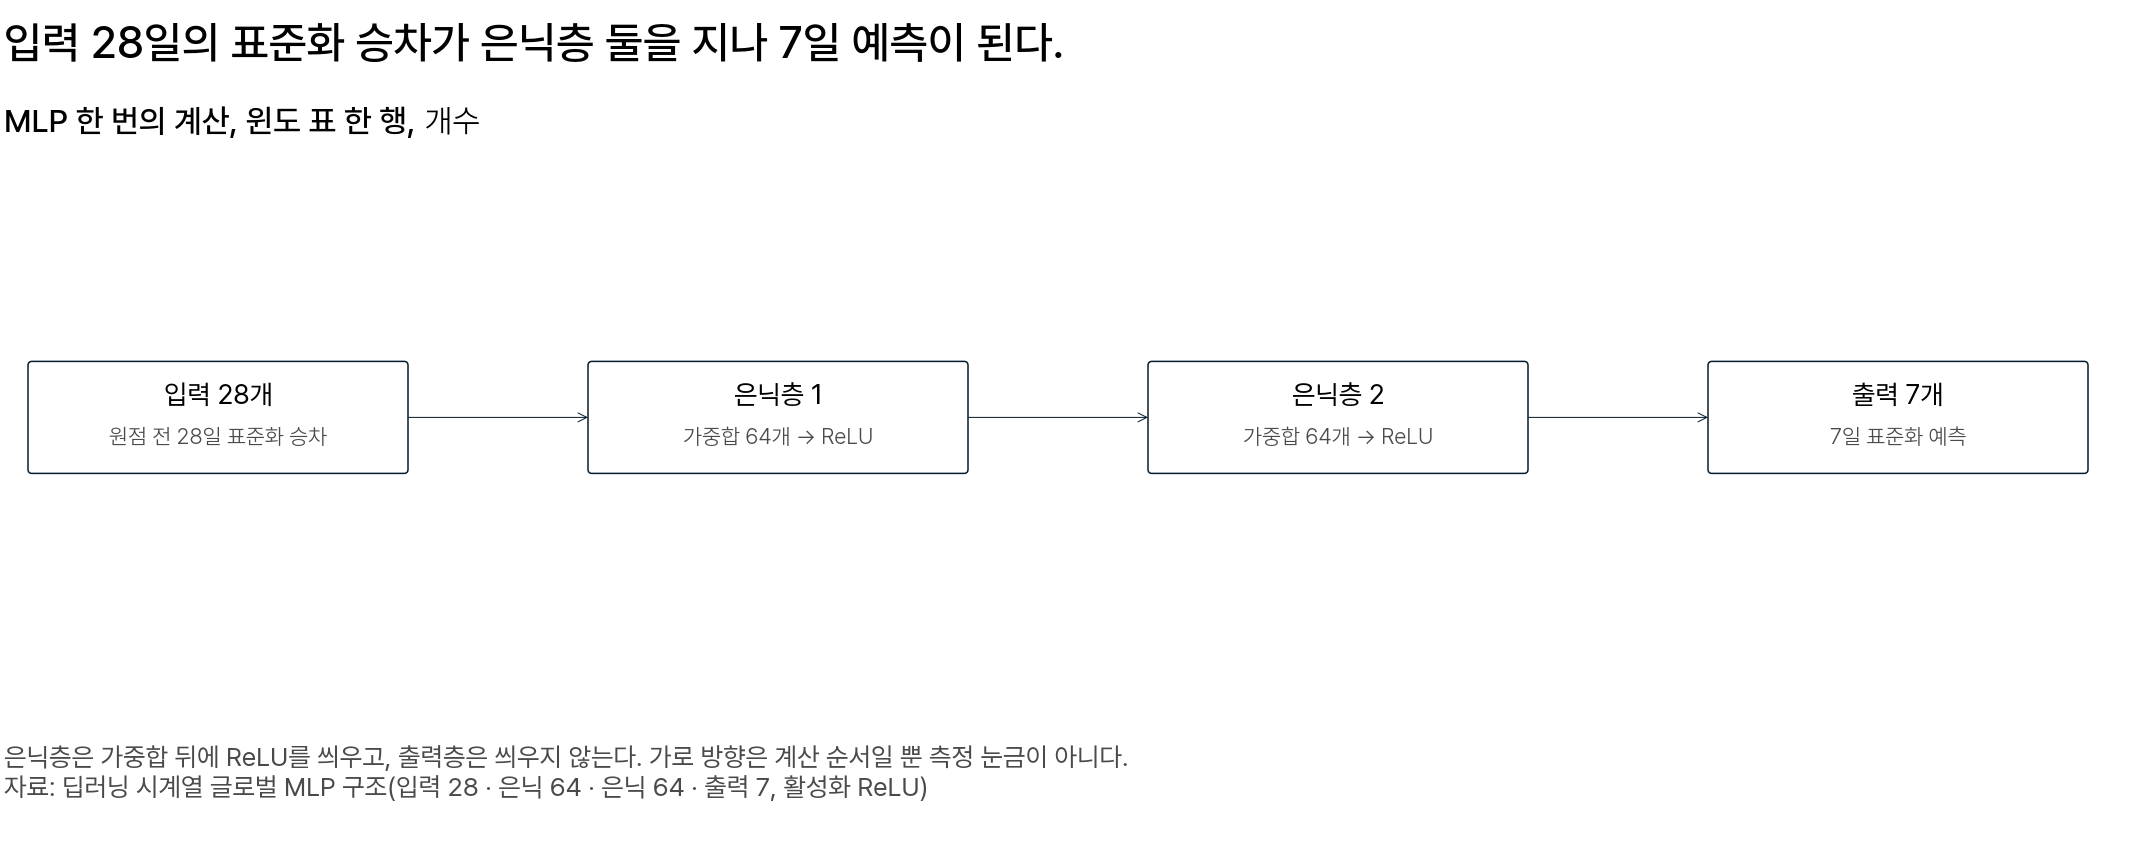

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ MLP 한 번의 계산. 상자는 층의 출력이고, 원점 전 28일의 표준화 승차가 은닉층 둘을 지나 7일의 표준화 예측이 된다</em></p>

가중치는 **손실(loss)** 이 줄어드는 쪽으로 조금씩 바꿔 정합니다. 손실은 예측이 틀린 정도를 숫자 하나로 모은 값입니다. 이 방법이 **경사하강법(gradient descent)** 입니다.

가중치 $w$ 하나로 입력 1 의 정답 2 를 맞힌다고 해 봅니다. 예측이 $w \times 1 = w$ 라 손실은 제곱 오차 $(2 - w)^2$ 입니다. $w = 0.5$ 이면 손실은 $1.5^2 = 2.25$ 입니다. $w$ 를 0.6 으로 키우면 손실이 $1.4^2 = 1.96$ 으로 줄어, $w$ 를 키우는 쪽으로 바꿉니다.

손실의 기울기(경사)로 이 방향을 구해 가중치를 거듭 바꾸므로 경사하강법이라 부릅니다.

**MLP 는 은닉층 둘을 거쳐 7일을 내고, 가중치는 PyTorch 같은 라이브러리가 경사하강법으로 정합니다.**

### 조기 종료와 시드 [필수]

학습은 언제 멈출까요? 학습 윈도를 한 번 다 읽는 것이 **에폭(epoch)** 입니다. 에폭을 늘리면 어느 때부터 학습 윈도에만 맞고 새 날에는 덜 맞는 **과적합(overfitting)** 이 생깁니다.

그래서 원점 직전 56일을 **검증 구간(validation period)** 으로 떼어 둡니다. **조기 종료(early stopping)** 는 이 구간의 손실이 5에폭 이어서 나아지지 않으면 멈추는 규칙입니다. 멈춘 뒤에는 가장 좋았던 에폭의 가중치로 되돌립니다.

검증 56일은 학습에 쓰지 않은 날이어야 새 날에 덜 맞기 시작하는 에폭을 찾을 수 있습니다. μ·σ 도 학습 입력을 바꾸는 데 쓰여, 검증 날의 값이 학습에 들어가지 않게 원점 57일 전까지로 구합니다.

로컬·글로벌 표의 4,158개는 원점 전날까지 센 윈도 수입니다. 가중치도 μ·σ 처럼 정답 7일이 검증 구간 앞에서 끝나는 윈도로만 학습합니다. 정답 끝날이 검증 구간 안인 윈도 56개를 빼면 역마다 4,158 − 56 = 4,102개, 100개 역 410,200개입니다.

<img src="https://commons.wikimedia.org/wiki/Special:FilePath/Overfitting_svg.svg" alt="가로축 학습 진행, 세로축 오차인 좌표에 계속 내려가는 파란 곡선과 내려갔다 다시 오르는 빨간 곡선, 빨간 곡선의 가장 낮은 곳에 세로선" width="610" height="450"/>
<p align="center"><em>▲ 가로축은 학습을 진행한 정도, 세로축 ε 는 오차다. 파란 선이 학습 오차, 빨간 선이 검증 오차이고, 가는 세로선이 검증 오차가 가장 낮은 곳이다. 조기 종료는 이 세로선의 가중치를 남긴다 (출처: Wikimedia Commons, Overfitting svg.svg)</em></p>

손실을 평균 제곱 오차(MSE)로 둔 글로벌 MLP 를 원점 2026-06-24 에서 학습해 봅니다. 멈출 에폭을 56일의 손실로 고르면 MASE 가 0.943 으로, 같은 원점의 계절 나이브 0.471 보다 더 빗나갑니다. 채점 7일의 손실로 고르면 0.710 으로 0.233 좋아 보이지만, 채점 7일을 본 누수입니다.

가중치는 처음에 난수로 정한 값에서 출발합니다. 학습 윈도는 에폭마다 난수로 정한 순서로 256개씩 읽으며 가중치를 바꿉니다. 이 두 난수의 출발값이 **시드(seed)** 이고, 시드가 바뀌면 학습이 끝난 가중치도 달라집니다.

같은 설정도 원점 2026-06-24 의 MASE 가 시드 0～4 에서 0.553～0.943 으로 움직입니다. 위 0.943 은 그 가운데 가장 큰 시드 0 의 값입니다.

두 설정이 한 가지만 다를 때는 시드 0～4 로 다섯 번 학습합니다. 손실을 MSE 로 둔 MLP 와 MAE 로 둔 MLP(「5. 손실 MSE 와 MAE」)가 그런 예입니다. 다섯 번 모두 같은 쪽이 낮을 때만 그쪽이 낫다고 말합니다.

<div class="lms-summary">

**정리**

MLP 는 가중합에 ReLU 를 씌운 층을 거쳐 7일을 내고, 가중치는 자료로 정합니다.

**할 일**

- 멈출 에폭은 검증 구간(원점 직전 56일)의 손실로 고르고, 채점 7일로 고르지 않습니다

두 설정은 시드 0～4 로 학습해 모든 시드에서 같은 방향인지 봅니다.

</div>

## 5. 손실 MSE 와 MAE

신경망을 학습할 때 손실은 MSE 와 MAE 가운데 무엇으로 둘까요?

### 손실 두 가지 [필수]

채점 지표로 본 MSE·MAE 를 학습에서는 손실로 씁니다. 두 손실이 쓰는 오차는 다음과 같습니다.

$$
e_k = y_k - \hat y_k
$$

- $y_k$: $k$ 번째 정답 값
- $\hat y_k$: $k$ 번째 값의 모델 예측
- $k$: 값의 번호(1～$N$)

MSE 는 오차 제곱의 평균입니다.

$$
\text{MSE} = \frac{1}{N}\sum_{k=1}^{N} e_k^{2}
$$

MAE 는 오차 크기의 평균입니다.

$$
\text{MAE} = \frac{1}{N}\sum_{k=1}^{N} |e_k|
$$

- $N$: 한 번에 비교하는 값의 개수(윈도 하나면 7)

MSE 와 MAE 는 둘 다 다음 질문에 답합니다.

> 지금 가중치로 낸 예측은 정답에서 평균 얼마나 빗나갔나?

**두 손실은 같은 오차 $e_k$ 를 MSE 는 제곱해서, MAE 는 크기 그대로 평균합니다.**

### 손실과 채점 지표 [필수]

**손실**은 학습할 때 모델이 줄이는 값이고, **채점 지표**는 학습 뒤 평가표에 적는 값입니다. 오차를 세는 방식이 같은 손실과 채점 지표를 함께 씁니다.

| 오차를 세는 방식 | 손실 | 채점 지표 |
|---|---|---|
| 제곱 | MSE | RMSE = $\sqrt{\text{MSE}}$ |
| 크기 | MAE | MAE, MASE = MAE ÷ $Q_i$ |

이렇게 함께 쓰는 까닭은 둘입니다.

- 제곱근은 크기 순서를 바꾸지 않습니다. MSE 가 4,000,000명² 과 9,000,000명² 인 두 예측은 RMSE 도 2,000명과 3,000명으로 순서가 같습니다. 그래서 MSE 를 가장 작게 하는 예측이 RMSE 도 가장 작게 합니다. 학습에는 계산이 간단한 MSE 를 쓰고, 평가표에는 명 단위로 읽을 수 있는 RMSE 를 적습니다.
- MASE 는 그 역의 MAE 를 정해진 수 $Q_i$ 로 나눈 값이라, MAE 를 줄이면 MASE 도 줄어듭니다. 잠실은 $Q_i$ 가 6,405.5명입니다. MAE 가 3,203명에서 2,000명으로 줄면 MASE 는 0.500 에서 0.312 로 줄어듭니다.

이틀 오차가 1,000명·3,000명이면 세 값은 이렇습니다.

| 값 | 계산 | 결과 | 읽는 법 |
|---|---|---:|---|
| MSE | (1,000² + 3,000²) ÷ 2 | 5,000,000명² | 단위가 명² 이라 그대로 읽기 어려움 |
| RMSE | √5,000,000 | 약 2,236명 | 약 2,236명 빗나감 |
| MAE | (1,000 + 3,000) ÷ 2 | 2,000명 | 하루 평균 2,000명 빗나감 |

RMSE 가 MAE 보다 큰 까닭은 제곱한 뒤 평균해, 크게 빗나간 날(3,000명)이 더 무겁게 들어가기 때문입니다.

서울 지하철 평가표에서 손실을 고르는 규칙은 이렇습니다.

$$
\textbf{채점 지표 MASE} \;\longrightarrow\; \textbf{손실 MAE}
$$

### 강남역 개천절이 있는 주의 다섯 날 [필수]

두 식이 어디서 달라지는지 2호선 강남역의 2025년 9월 29일～10월 3일 평일 다섯 날(월～금)로 봅니다. 마지막 날은 개천절입니다.

| 날 | 9/29 월 | 9/30 화 | 10/1 수 | 10/2 목 | 10/3 금(개천절) |
|---|---:|---:|---:|---:|---:|
| 승차 $y_k$ (천 명) | 88.4 | 90.4 | 89.9 | 89.7 | 43.7 |

손실이 예측을 어느 쪽으로 움직이는지 보려고, 모델이 다섯 날 모두에 같은 값 하나를 낸다고 단순하게 놓습니다. 이 예측값을 $c$ 라 부르면 오차는 $e_k = y_k - c$ 입니다.

예를 들어 $c = 90$ 이면 다섯 날의 오차는 −1.6 · 0.4 · −0.1 · −0.3 · −46.3천 명입니다. 제곱해 평균하면 MSE 는 약 429.3(천 명)² 이고, 크기를 평균하면 MAE 는 9.74천 명입니다.

$c$ 를 바꿔 가며 이렇게 세어, MSE 나 MAE 가 가장 작은 $c$ 를 찾습니다.

> **[예측] 다섯 날의 MSE 를 가장 작게 하는 $c$ 는 어디에 있을까요?**
>
> 1. 개천절이 아닌 네 날의 값 근처(88～90천 명)
> 2. 네 날보다 낮은 곳(80천 명 근처)
> 3. 개천절 하루의 값 근처(44천 명)
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

두 후보 $c$ 를 식에 대입해 봅니다.

| 한 값 $c$ | MSE ((천 명)²) | MAE (천 명) |
|---|---:|---:|
| 80.42 (다섯 날의 평균) | 337.53 | 14.69 |
| 89.7 (다섯 날의 중앙값) | 423.64 | 9.64 |

MSE 는 평균 80.42 에서 더 작고, MAE 는 중앙값 89.7 에서 더 작습니다. 평균 80.42 는 다섯 날 합 402.1 을 5 로 나눈 값입니다. 네 날의 값보다 8천 명 가까이 아래이니 둘째 보기가 맞습니다.

아래 코드를 ▶ 로 실행하면 $c$ 를 40～95천 명에서 0.01 간격으로 옮기며, 두 손실이 가장 작은 곳을 찾습니다.

In [ ]:
# 다섯 날을 한 값 c 로 예측할 때 MSE·MAE 가 가장 작은 c 찾기
import numpy as np

y = np.array([88.4, 90.4, 89.9, 89.7, 43.7])   # 강남역 2025-09-29 ~ 10-03 승차(천 명)
cs = np.arange(4000, 9501) / 100                # 후보 c: 40.00 ~ 95.00, 0.01 간격

err = y[None, :] - cs[:, None]                  # 행 = 후보 c, 열 = 날
mse = (err ** 2).mean(axis=1)
mae = np.abs(err).mean(axis=1)

print(f"MSE 가 가장 작은 c = {cs[mse.argmin()]:.2f}  (다섯 날 평균 {y.mean():.2f})")
print(f"MAE 가 가장 작은 c = {cs[mae.argmin()]:.2f}  (다섯 날 중앙값 {np.median(y):.2f})")

sq = (y - y.mean()) ** 2                        # 평균에서 계산한 제곱 오차 다섯 개
print(f"개천절 하루가 제곱 오차 합에서 차지하는 비중 = {sq[-1] / sq.sum():.1%}  "
      f"(네 날 {sq[:4].sum():.2f}, 개천절 {sq[-1]:.2f})")

5,501개 후보를 모두 계산해도 결과는 80.42 와 89.7 입니다. `y` 배열의 `43.7` 을 `89.0` 으로 바꿔 다시 실행하면 두 값이 89 근처에서 거의 만납니다.

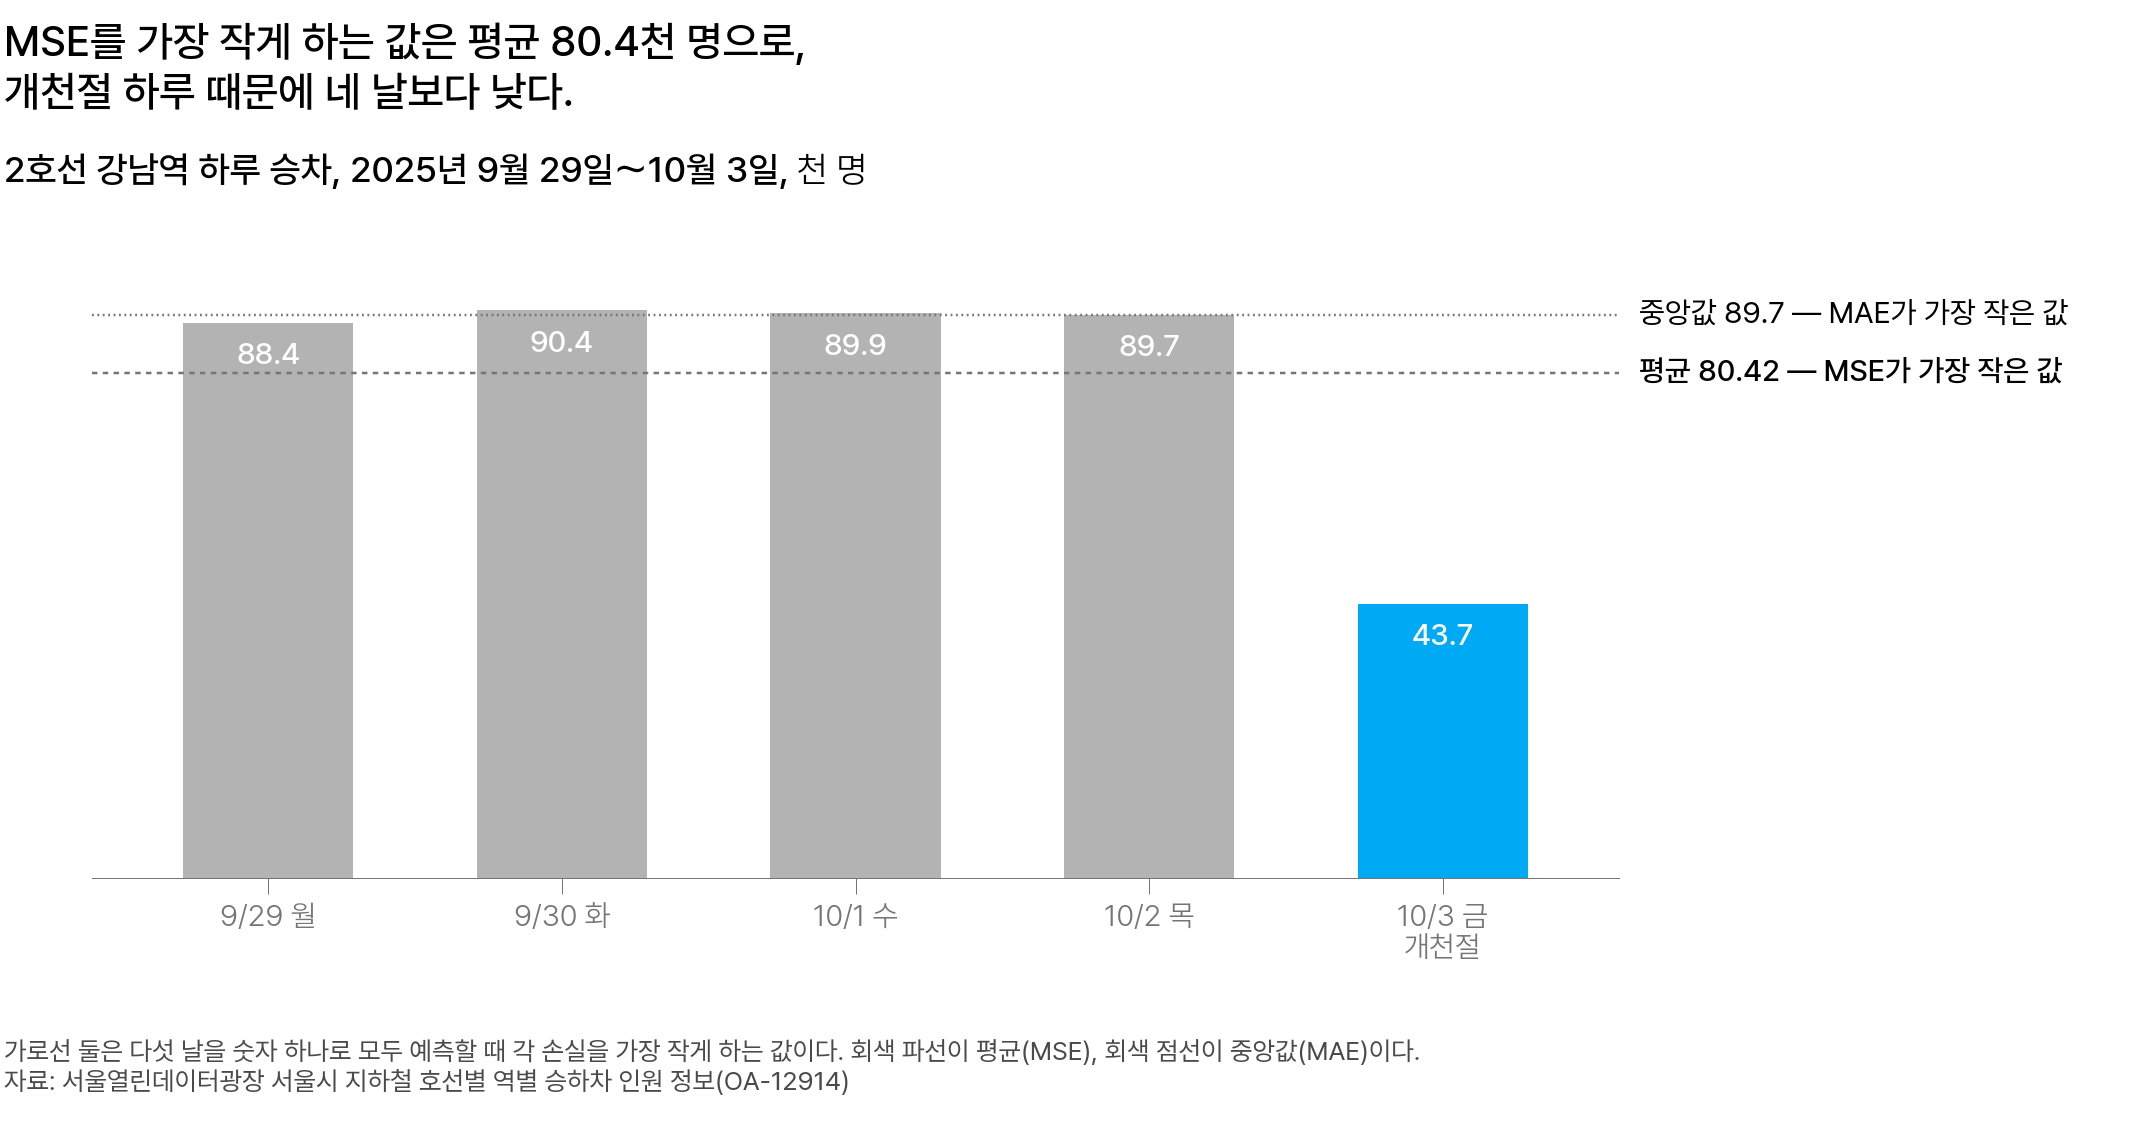

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 2025년 9월 29일 월요일부터 10월 3일 금요일 개천절까지 평일 다섯 날이고, 세로축은 강남역 하루 승차(천 명)다. 두 가로선은 다섯 날을 숫자 하나로 예측할 때 두 손실이 가장 작아지는 값이다. 하늘색 개천절 하루 때문에 MSE 를 가장 작게 하는 값(회색 파선 80.42)은 네 날보다 낮고, MAE 를 가장 작게 하는 값(회색 점선 89.7)은 네 날 높이에 있다</em></p>

**그래서 개천절이 아닌 네 날을 맞히려면 MAE 로 학습합니다.**

### 평균과 중앙값 [필수]

왜 MSE 를 가장 작게 하는 값은 네 날보다 낮아질까요?

네 날이 88～90천 명이니 그 근처가 좋아 보입니다. 그 생각은 MAE 기준으로는 맞습니다.

- MAE: 오차 크기의 합. 대부분의 날에 가까운 값이 유리합니다
- MSE: 오차 제곱의 합. 크게 빗나간 하루를 줄이는 값이 유리합니다

예를 들어 네 날이 100, 하루가 50 이면 이렇습니다.

| 한 값 $c$ | 오차 크기 | 크기 합 | 제곱 합 |
|---|---|---:|---:|
| 100 | 0 · 0 · 0 · 0 · 50 | 50 | 2,500 |
| 90 (평균) | 10 · 10 · 10 · 10 · 40 | 80 | 2,000 |

$c$ 를 100 에서 90 으로 내리면 하루의 제곱은 2,500 에서 1,600 으로 900 줄어듭니다. 네 날의 제곱은 100씩, 합쳐 400 늘어납니다. 그래서 크기의 합은 늘어도 제곱의 합은 줄어듭니다.

강남역 다섯 날을 평균 80.42 로 예측하면, 네 날의 합과 개천절 하루의 오차는 이렇습니다.

| 오차 | 네 날 합 | 개천절 하루 | 개천절 하루의 비중 |
|---|---:|---:|---:|
| 오차 크기 | 36.72 | 36.72 | 50% |
| 오차 제곱 | 339.27 | 1,348.36 | 79.9% |

각 값에서 평균을 뺀 값을 다 더하면 0 이라, 평균보다 큰 날의 오차 합과 작은 날의 오차 합이 늘 같습니다. 이 다섯 날에서는 둘 다 36.72 라, 크기로 세면 개천절 하루가 네 날 합과 같습니다. 제곱으로 세면 네 날 합의 약 4배입니다. 그래서 MSE 를 줄이려면 이 하루의 오차부터 줄여야 합니다.

두 손실의 좋은 점과 약한 점을 강남 다섯 날의 수로 정리하면 이렇습니다.

| 손실 | 무엇을 재나(단위) | 좋은 점 | 약한 점 | 이럴 때 쓴다 |
|---|---|---|---|---|
| MSE | 오차 제곱의 평균(단위: 승차 인원의 제곱) | 큰 오차를 제곱해 훨씬 크게 세므로 크게 빗나가는 날을 먼저 줄인다 | 드문 날 하나 때문에 나머지 날의 예측도 바뀐다(개천절 하나 때문에 80.42, 다른 네 날보다 8～10천 명 낮음) | 드문 큰 오차의 비용이 크고 RMSE 로 채점할 때 |
| MAE | 오차 크기의 평균(단위: 승차 인원) | 드문 날 하나가 나머지 날의 예측을 바꾸지 않는다(89.7, 네 날과 0～1.3천 명 차이) | 드문 날은 크게 빗나간다(개천절 실제 43.7 을 89.7 로 예측, 46.0천 명 차이) | 공휴일이 아닌 대부분의 날을 맞히는 것이 중요하고 MAE 나 MASE 로 채점할 때 |

<details class="lms-extra"><summary>자세히 — MSE 는 왜 평균에서, MAE 는 왜 중앙값에서 가장 작아지나</summary>

평균 80.42 로 예측할 때 날마다의 오차는 이렇습니다.

| 날 | 9/29 | 9/30 | 10/1 | 10/2 | 10/3(개천절) | 합 |
|---|---:|---:|---:|---:|---:|---:|
| 오차 크기 | 7.98 | 9.98 | 9.48 | 9.28 | 36.72 | 73.44 |
| 제곱 | 63.68 | 99.60 | 89.87 | 86.12 | 1,348.36 | 1,687.63 |

본문 표의 네 날 합은 9/29～10/2 의 값을 더한 것입니다.

MSE 의 정의에 예측 $c$ 를 대입합니다.

$$
\text{MSE}(c) = \frac{1}{5}\sum_{k=1}^{5}(y_k - c)^2
$$

$c$ 를 아주 조금 옮길 때 MSE 가 변하는 비율, 곧 $c$ 에 대한 미분을 구합니다. 한 항 $(y_k - c)^2$ 은 $u = y_k - c$ 를 구한 뒤 제곱하는 합성함수라, 합성함수의 미분인 **연쇄 법칙(chain rule)** 을 씁니다. $y_k$ 는 정해진 값이라 $c$ 가 1 늘면 $u$ 는 1 줄어, 안쪽 미분은 $-1$ 입니다.

$$
\begin{aligned}
\text{바깥 미분:}\quad \frac{d}{du}u^2 &= 2u \\
\text{안쪽 미분:}\quad \frac{du}{dc} &= -1 \\
\text{연쇄 법칙(바깥 미분 } \times \text{ 안쪽 미분):}\quad \frac{d}{dc}(y_k - c)^2 &= 2u \times (-1) \\
\text{곱 정리:}\quad &= -2u \\
u \text{ 에 } y_k - c \text{ 대입:}\quad &= -2(y_k - c)
\end{aligned}
$$

다섯 항을 더해 5 로 나누면 MSE 의 기울기입니다.

$$
\frac{d\,\text{MSE}}{dc} = -\frac{2}{5}\sum_{k=1}^{5}(y_k - c)
$$

가장 작은 곳에서는 이 비율이 0 입니다. 양변을 $-\tfrac{2}{5}$ 로 나눕니다.

$$
\sum_{k=1}^{5}(y_k - c) = 0
$$

합을 항마다 나눠 적습니다. $c$ 는 다섯 날 모두 같은 값이라 다섯 번 더하면 $5c$ 입니다.

$$
\sum (y_k - c) = \sum y_k - 5c
$$

다섯 날 값의 합 402.1 을 대입합니다.

$$
402.1 - 5c = 0
$$

양변에 $5c$ 를 더하고 5 로 나눕니다. $c = 402.1 \div 5 = 80.42$ 로, 다섯 날의 평균입니다.

MAE 는 미분 대신 $c$ 를 0.1 옮겨 봅니다. $c = 80.42$ 에서 $c$ 를 0.1 키우면 $c$ 보다 큰 네 날은 오차 크기가 0.1씩 줄고, 개천절 하루만 0.1 늡니다. 오차 크기의 합이 0.4 − 0.1 = 0.3 줄고, MAE 는 0.3 ÷ 5 = 0.06 줄어듭니다.

$c$ 보다 큰 날이 작은 날보다 많은 동안에는 $c$ 를 키울수록 MAE 가 줄어듭니다. 큰 날과 작은 날의 수가 같아지는 곳은 가운데 날인 89.7 입니다. 그래서 MSE 는 오차의 합이 0 인 평균에서, MAE 는 $c$ 보다 큰 날과 작은 날이 같은 수인 중앙값에서 가장 작습니다.

<img src="https://en.wikipedia.org/wiki/Special:FilePath/Relationship_between_mean_and_median_under_different_skewness.png" alt="오른쪽 꼬리·대칭·왼쪽 꼬리 분포에서 평균과 중앙값의 위치" width="648" height="245"/>
<p align="center"><em>▲ 가로축이 값, 세로축이 그 값이 나오는 빈도다. 세로선은 최빈값(Mode, 가장 자주 나오는 값)·중앙값(Median)·평균(Mean)이다. 왼쪽처럼 오른쪽 꼬리가 길면 평균은 중앙값보다 꼬리 쪽에 있고, 중앙값은 값이 몰린 곳 가까이에 있다 (출처: Wikimedia Commons, Relationship between mean and median under different skewness)</em></p>

개천절이 있는 주는 오른쪽 그림처럼 왼쪽 꼬리가 긴 경우입니다. 작은 값 43.7 하나 때문에 평균 80.42 는 네 날보다 8～10천 명 낮아집니다. 중앙값은 개천절 값이 43.7 이든 평소 날처럼 89.0 이든 89.7 그대로입니다.

</details>

<div class="lms-summary">

**정리**

한 값으로 예측하면 MSE 는 평균에서, MAE 는 중앙값에서 가장 작습니다.

**할 일**

- 드문 날이 있는 자료에서는 MSE 와 MAE 로 각각 학습해, 드문 날이 없는 주의 MASE 를 견줍니다

크게 빗나간 날이 하루 있으면 MSE 로 고른 값만 그날 쪽으로 움직입니다.

</div>

### 100개 역 학습 윈도의 평일 공휴일 [필수]

드문 날 하나 때문에 나머지 날의 예측이 낮아지는 일은 100개 역의 학습 윈도에서도 일어납니다. 입력 28일에는 다음 주가 공휴일인지 적혀 있지 않습니다. 그래서 입력이 비슷해도 정답 7일에 평일 공휴일이 있는 윈도와 없는 윈도가 함께 있습니다.

예를 들어 입력이 같은 윈도 10개 가운데 9개는 정답이 100, 공휴일인 1개는 50 이라면 예측은 하나입니다. MSE 는 평균 95, MAE 는 중앙값 100 을 고르고, MSE 의 95 는 공휴일이 아닌 9개에서 5 모자랍니다.

원점 2026-06-24 의 학습 윈도에서 정답(출력 7일) 값 가운데 평일 공휴일의 값은 3.8% 입니다. 이 3.8% 가 MSE 로 학습한 MLP 에서는 손실의 59.7%, MAE 로 학습한 MLP 에서는 32.6% 를 차지합니다. 그래서 MSE 로 학습하면 공휴일이 아닌 날까지 낮게 예측합니다.

MAE 로 학습하면 공휴일 오차는 크게 남지만, 위 예처럼 중앙값 100 을 골라 나머지 9개에 맞습니다.

<details class="lms-extra"><summary>더 깊이 — NeuralForecast 에서 같은 설정의 이름</summary>

실습은 학습 설정을 함수 `fit_global` 하나에 담았습니다. 시계열 신경망 라이브러리 NeuralForecast 에서는 같은 설정을 이런 이름으로 씁니다.

| 하는 일 | 실습의 `fit_global` | NeuralForecast 3.2.1 |
|---|---|---|
| 입력 28일 · 출력 7일 · 은닉층 64 둘 | 함수 안에 고정 | `MLP(h=7, input_size=28, num_layers=2, hidden_size=64)` |
| 계열별 표준화 | 함수 안에서 원점 57일 전까지로 구함 | `NeuralForecast(models, freq="D", local_scaler_type="standard")` |
| 손실 | `loss="mae"` | `loss=MAE()`(MLP 의 기본값) |
| 검증 구간 | 56일 고정 | `nf.fit(df, val_size=56)` |
| 조기 종료 | 5에폭 고정 | `early_stop_patience_steps=5`(에폭 수가 아니라 가중치를 `val_check_steps` 번 옮길 때마다 하는 검증의 횟수) |
| 시드 | `seed=0` | `random_seed=0`(기본값 1) |

</details>

<div class="lms-summary">

**정리**

채점을 MASE 로 하면 손실도 MAE 로 둡니다.

**할 일**

- 실습의 학습 함수 `fit_global` 은 `loss="mae"` 로 부릅니다

그러면 실습 코드 안의 PyTorch 손실이 `nn.MSELoss()` 에서 `nn.L1Loss()`(PyTorch 에서 MAE 손실의 이름)로 바뀝니다.

</div>

> **[문제] 강남역 개천절이 있는 주의 다섯 날(88.4 · 90.4 · 89.9 · 89.7 · 43.7천 명)을 숫자 하나로 예측할 때, MSE 를 가장 작게 하는 값이 개천절이 아닌 네 날보다 낮은 80.42 로 내려간 이유로 맞는 것은?**
>
> 1. 다섯 날 가운데 공휴일이 하나라서 MSE 가 그날을 한 번 더 더한다
> 2. 오차를 제곱하면 크게 빗나간 개천절 하루가 제곱 오차 합의 79.9% 를 차지해, 그 하루의 오차를 줄이는 쪽으로 값이 낮아진다
> 3. MSE 는 값이 작은 날에 무게를 더 주도록 만든 손실이다

## 6. 평가표와 모델 선택

다음 주 역별 인력을 정하는 데 평가표의 네 방식 가운데 어느 예측을 쓸까요?

공휴일 없는 두 주를 먼저 보고, 공휴일 있는 세 주를 다음에 봅니다. 운영하는 주의 80% 가 평일 공휴일이 없는 주이기 때문입니다.

### 네 방식의 역 단위 MASE [필수]

두 MLP 는 구조·조기 종료·시드가 같고 손실만 다릅니다. 두 모델의 이름을 줄여 MLP(MSE 손실)·MLP(MAE 손실)이라 부릅니다.

> **[예측] 손실만 MAE 로 바꾼 MLP 는 공휴일 없는 두 주에서 계절 나이브 0.445 보다 작게 빗나갈까요?**
>
> 1. 작게 빗나간다
> 2. 비슷하다
> 3. 크게 빗나간다
>
> 답을 정한 뒤 아래를 읽어 보세요(정답 채점은 없습니다).

하나를 고른 뒤 아래 그림을 봅니다.

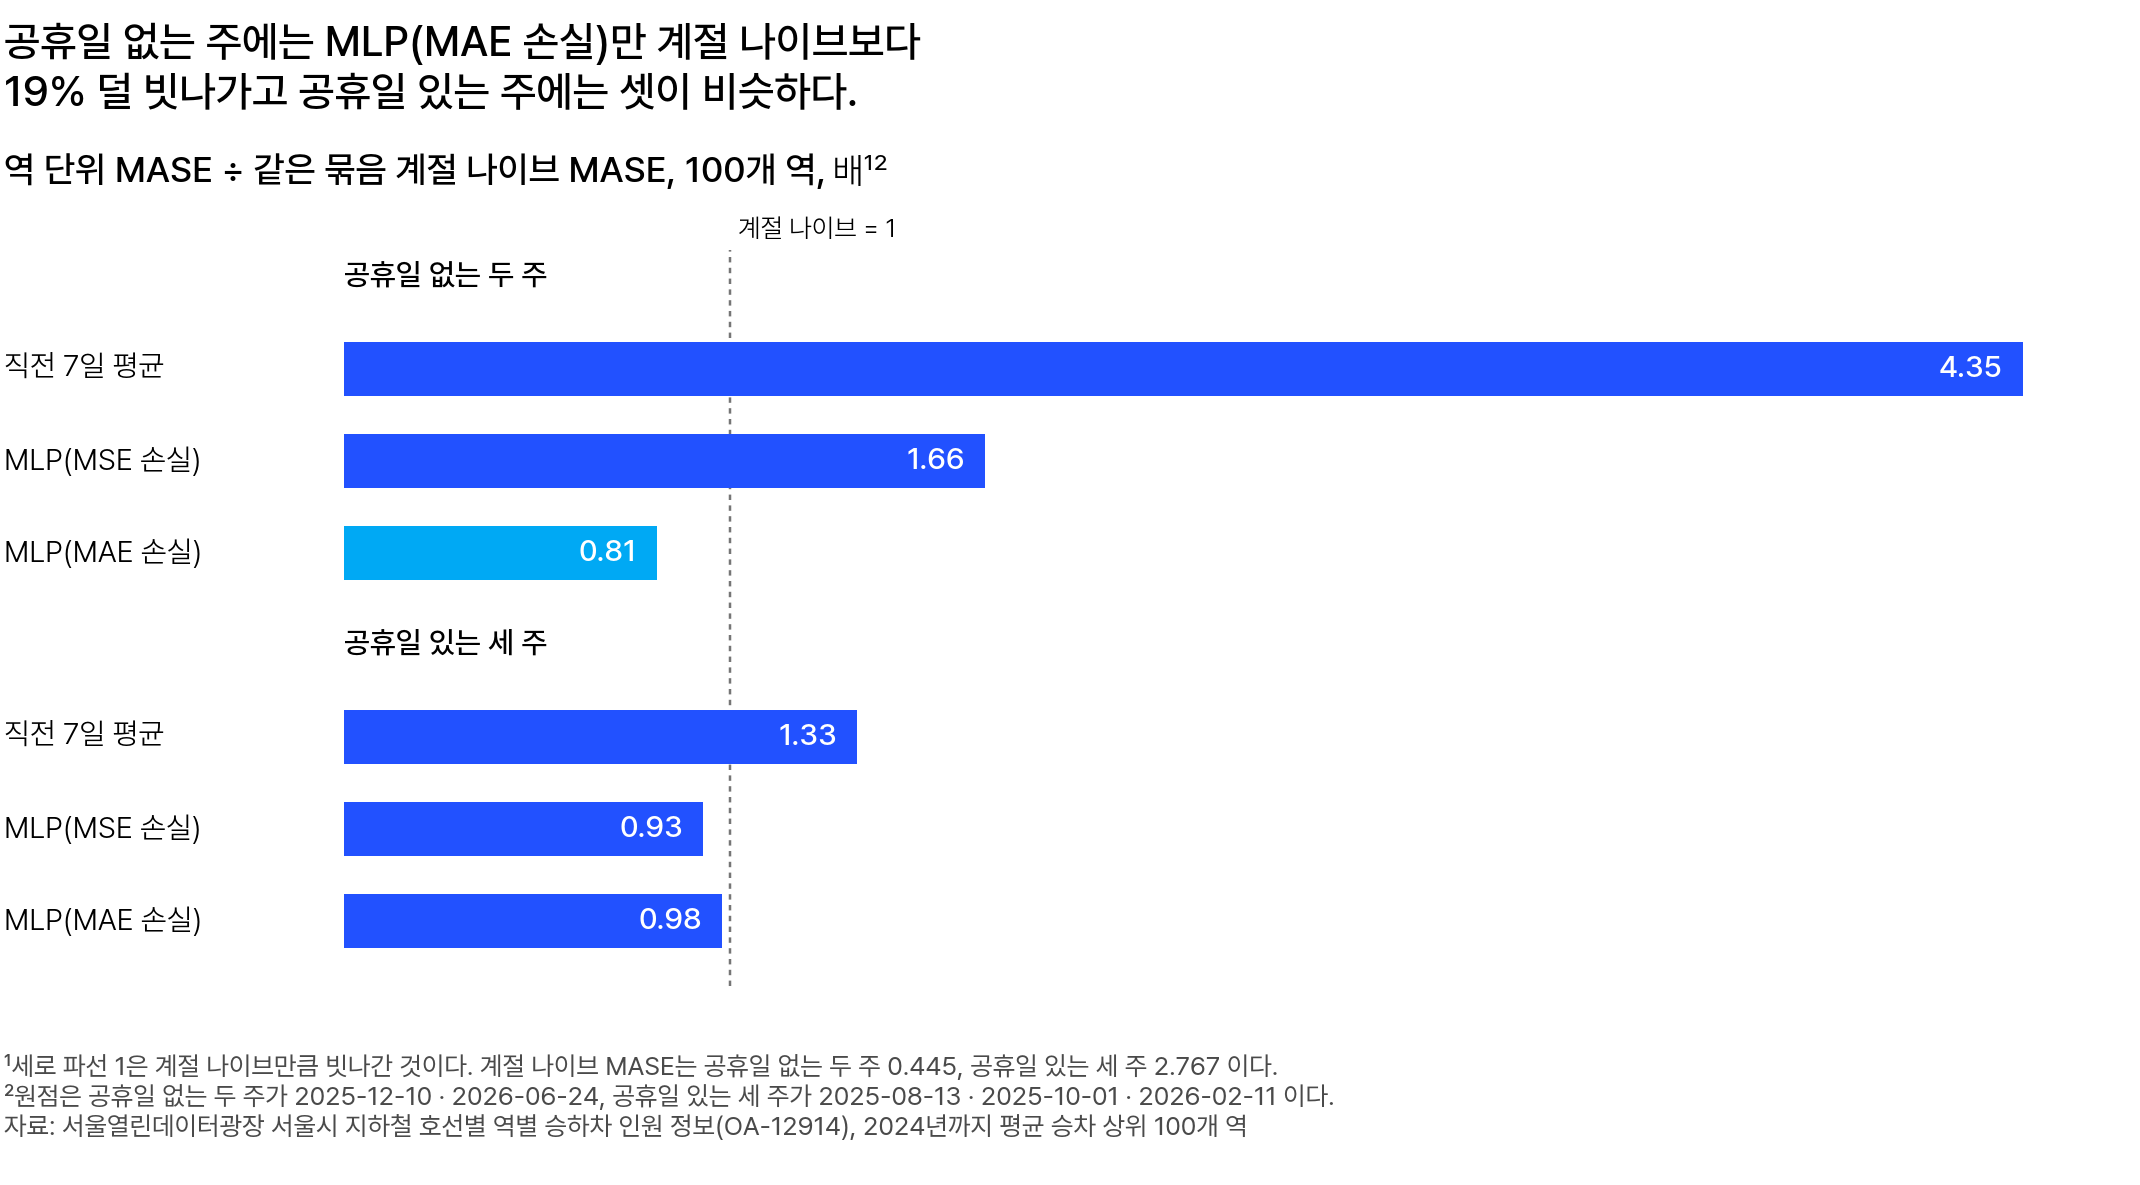

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 가로축은 같은 묶음 계절 나이브 대비 배수다. 평가표 세 방식의 역 단위 MASE 를 같은 묶음 계절 나이브의 MASE 로 나눈 값이고, 위는 공휴일 없는 두 주, 아래는 공휴일 있는 세 주다. 회색 세로 파선 1 은 계절 나이브만큼 빗나간 것이고, 막대가 이 선보다 짧으면 계절 나이브보다 덜 빗나간 방식이다. 하늘색 막대가 공휴일 없는 두 주의 MLP(MAE 손실)이다</em></p>

공휴일 없는 두 주에서 막대가 1 보다 짧은 방식은 MLP(MAE 손실) 하나이고, 답은 첫째 보기입니다. 공휴일 있는 세 주에서는 두 MLP 가 0.93·0.98 로 1 에 가깝습니다.

그림의 배수는 아래 표의 MASE 를 같은 묶음의 계절 나이브로 나눈 값입니다(0.359 ÷ 0.445 ≈ 0.81). 평가표에는 원점 5개 평균도 함께 적지만, 모델은 두 묶음으로 고릅니다. 그래서 아래 표에는 두 묶음만 두고 원점 5개 평균은 「더 깊이」 상자에 두었습니다.

| 방식 | 공휴일 없는 두 주 | 공휴일 있는 세 주 |
|---|---:|---:|
| 계절 나이브 | 0.445 | 2.767 |
| 직전 7일 평균 | 1.935 | 3.684 |
| 글로벌 MLP(MSE 손실) | 0.739 | 2.587 |
| **글로벌 MLP(MAE 손실)** | **0.359** | 2.717 |

**두 묶음의 결과가 달라, 모델 선택도 공휴일 없는 주와 공휴일 있는 주로 나눠 정합니다.**

### 공휴일 없는 두 주 [필수]

공휴일 없는 주에 쓸 후보는 MLP(MAE 손실)입니다. 0.359 로 계절 나이브 0.445 보다 19% 덜 빗나갔습니다. 시드 0～4 로 다시 학습해도 0.356～0.372 로 모두 0.445 보다 낮습니다.

MLP(MSE 손실)은 0.739 로 계절 나이브보다 66% 더 빗나갔습니다. 실제보다 낮게 예측하기 때문입니다. 공휴일 없는 두 주의 예측 표는 100개 역 × 7일 × 2 = 1,400행이고, 한 행은 한 역의 하루입니다. 아래는 원점 2025-12-10 강남의 앞 5일입니다.

| 날짜 | 실제 | 계절 나이브 | MLP(MSE 손실) | MLP(MAE 손실) |
|---|---:|---:|---:|---:|
| 12/10 수 | 91,977 | 89,609 | 88,036 | 93,159 |
| 12/11 목 | 93,905 | 96,709 | 90,601 | 94,540 |
| 12/12 금 | 101,091 | 99,429 | 92,979 | 97,836 |
| 12/13 토 | 71,128 | 67,899 | 65,353 | 67,846 |
| 12/14 일 | 41,209 | 39,487 | 37,758 | 39,995 |

MLP(MSE 손실)은 다섯 날 모두 실제보다 작고, 세 방식 가운데 가장 작습니다. 1,400행 전체에서는 MLP(MSE 손실)의 87.2% 가 실제보다 작은 **과소 예측**이었습니다. MLP(MAE 손실)은 60.5%, 계절 나이브는 52.6% 입니다. MLP(MSE 손실)대로 인력을 두면 대부분의 역과 날에 사람이 모자랍니다.

낮게 예측하는 까닭은 「5. 손실 MSE 와 MAE」에서 본 손실에 있습니다. MSE 로 학습하면 정답 값의 3.8% 인 평일 공휴일이 손실의 59.7% 를 차지해, 공휴일이 아닌 날까지 낮게 예측합니다. 시드 0～4 에서도 MLP(MSE 손실)은 0.571～0.739 로 모두 0.445 보다 커, 이 차이는 시드 탓이 아닙니다.

<details class="lms-extra"><summary>더 깊이 — 원점 5개 평균과 원점별·시드별 MASE</summary>

원점 5개를 한꺼번에 평균한 MASE 는 이렇습니다.

| 방식 | 원점 5개 평균 |
|---|---:|
| 계절 나이브 | 1.838 |
| 직전 7일 평균 | 2.984 |
| 글로벌 MLP(MSE 손실) | 1.848 |
| 글로벌 MLP(MAE 손실) | 1.774 |

원점별 MASE 는 이렇습니다.

| 방식 | 08-13 | 10-01 | 12-10 | 02-11 | 06-24 |
|---|---:|---:|---:|---:|---:|
| 계절 나이브 | 1.069 | 4.388 | 0.419 | 2.844 | 0.471 |
| 직전 7일 평균 | 2.180 | 4.881 | 1.919 | 3.991 | 1.950 |
| 글로벌 MLP(MSE 손실) | 1.062 | 4.047 | 0.536 | 2.653 | 0.943 |
| 글로벌 MLP(MAE 손실) | 1.067 | 4.322 | 0.326 | 2.762 | 0.393 |

두 묶음 평균은 반올림 전 값으로 구해, 이 표의 값으로 평균하면 0.001 다를 수 있습니다. 두 MLP 는 CPU 에서 시드 0 으로 한 번 학습한 값입니다. 기기가 바뀌면 값이 조금 달라집니다. Colab T4 GPU 에서는 MLP(MSE 손실) 원점 2026-06-24 가 0.897 이었습니다.

시드 0～4 로 다시 학습한 원점 5개 평균은 이렇습니다.

| 방식 | 시드 0 | 시드 1 | 시드 2 | 시드 3 | 시드 4 |
|---|---:|---:|---:|---:|---:|
| 글로벌 MLP(MSE 손실) | 1.848 | 1.779 | 1.821 | 1.806 | 1.771 |
| 글로벌 MLP(MAE 손실) | 1.774 | 1.783 | 1.790 | 1.782 | 1.784 |

계절 나이브는 학습하지 않아 시드와 관계없이 1.838 입니다. MLP(MAE 손실)은 1.774～1.790 으로 다섯 시드 모두 1.838 보다 낮습니다. 두 MLP 를 견주면 시드 1·4 에서는 MLP(MSE 손실)이 더 낮아, 원점 5개 평균으로는 어느 쪽이 나은지 말할 수 없습니다.

</details>

**공휴일 없는 주의 후보는 MLP(MAE 손실)이고, 손실을 MSE 로 둔 MLP 는 쓰지 않습니다.**

### 공휴일 있는 세 주 [필수]

공휴일 있는 세 주에는 어느 MLP 도 계절 나이브보다 낫다는 근거가 없습니다. MLP(MSE 손실) 2.587, MLP(MAE 손실) 2.717, 계절 나이브 2.767 로 셋이 비슷합니다. 셋 모두 $Q_i$ 의 2.6～2.8배를 빗나갑니다. 이 오차는 대부분 평일 공휴일 6일에서 나옵니다.

까닭은 입력에 있습니다. 입력 28일 어디에도 다음 주가 공휴일인지 적혀 있지 않습니다. 그래서 평일 공휴일 예측 600개(100개 역 × 6일)는 두 MLP 모두 99.0% 가 실제보다 컸습니다.

원점 2025-10-01 의 강남이면 MLP(MAE 손실)은 10월 3일 금요일 개천절을 96,697명으로 예측했습니다. 1주일 전 금요일 값을 옮긴 계절 나이브는 97,311명이고, 실제는 43,721명입니다.

MLP(MSE 손실)이 2.587 로 조금 작은 것은 평소 낮게 예측하기 때문입니다. 평일 공휴일은 실제 승차가 크게 낮아 낮게 예측하는 쪽이 덜 빗나갈 뿐, 공휴일을 알아서가 아닙니다.

<details class="lms-extra"><summary>더 깊이 — 공휴일 있는 세 주의 채점 21일을 평일 공휴일과 나머지로 나눈 MASE</summary>

공휴일 있는 세 주의 채점 21일을 평일 공휴일 6일과 나머지 15일로 나눠 평균 MASE 를 구하면 이렇습니다.

| 채점하는 날 | 예측 수 | MLP(MSE 손실) | MLP(MAE 손실) | 계절 나이브 |
|---|---:|---:|---:|---:|
| 평일 공휴일 6일 | 600 | 6.904 | 7.449 | 7.473 |
| 나머지 15일 | 1,500 | 0.860 | 0.824 | 0.885 |

나머지 15일에서는 세 방식 모두 1 보다 작고 MLP(MAE 손실)이 가장 작습니다. 평일 공휴일 6일에서는 세 방식 모두 7 안팎이라, 공휴일 있는 세 주의 평균 2.6～2.8 은 대부분 이 6일에서 나옵니다.

평일 공휴일의 정답 값은 학습 윈도에서 지우지 않습니다. 잘못 적힌 값이 아니고, 예측하는 기간에도 다시 오기 때문입니다.

</details>

<div class="lms-summary">

**정리**

공휴일 없는 주의 역별 인력 예측 후보는 MLP(MAE 손실)입니다. 공휴일 없는 두 주에서 0.359 로 계절 나이브 0.445 보다 19% 덜 빗나갔고, 시드 0～4 에서도 모두 낮습니다. MLP(MSE 손실)은 예측의 87.2% 가 실제보다 작아 인력이 모자랍니다. 공휴일 있는 주에는 어느 MLP 도 계절 나이브보다 낫다는 근거가 없습니다(2.587 · 2.717 대 2.767).

**할 일**

- 손실을 채점 지표에 맞춥니다(실습의 학습 함수 `fit_global` 은 `loss="mae"`)
- 두 설정은 시드 0～4 모두 같은 방향인지 보고 어느 쪽이 나은지 말합니다

공휴일 있는 주에 어느 예측을 쓸지는 수업의 팀 라운드에서 정합니다.

</div>

### 오늘 배운 것: 글로벌 모델을 쓸 때 지킬 것 [필수]

윈도를 자르는 데서 모델을 고르는 데까지, 글로벌 모델로 역별 예측을 낼 때 지킬 것을 차례대로 모으면 이렇습니다.

| 번호 | 지킬 것 | 서울 지하철 100개 역에서 |
|---|---|---|
| 1 | 채점할 7일의 값은 어디에도 넣지 않음 | 윈도·MASE 분모 $Q_i$ 는 원점 전날까지, μ·σ 는 원점 57일 전까지의 자료로 만듦 |
| 2 | 윈도는 역마다 따로 자른 뒤 한 표로 합침 | 역 경계의 윈도에 두 역 값이 섞이지 않음 |
| 3 | 규모가 다른 역은 역마다 표준화 | 큰 역이 제곱오차를 차지하지 않음 |
| 4 | 입력 길이는 계절 주기 7일 이상 | 입력에 1주일 전 같은 요일 값이 있음 |
| 5 | 손실은 채점 지표에 맞춤 | MASE 로 채점하므로 MAE |
| 6 | 계절 나이브와 같은 원점·채점 단위로 견줌 | 원점 5개, 역 단위 MASE, 두 묶음으로 나눠 읽음 |
| 7 | 두 설정은 시드 0～4 모두 같은 방향인지 본 뒤 어느 쪽이 나은지 말함 | 공휴일 없는 두 주에서 시드 0～4 모두 MLP(MAE 손실)만 계절 나이브보다 낮음 |
| 8 | 드물게 크게 다른 값은 학습 윈도에서 지우지 않음 | 평일 공휴일은 예측하는 기간에도 다시 옴([fpp3 13.9 「이상치와 결측값 다루기」](https://otexts.com/fpp3/missing-outliers.html)) |

**채점할 7일을 어디에도 넣지 않고 계절 나이브와 같은 원점·같은 지표로 견줘야 평가표의 MASE 를 믿을 수 있습니다.**

> **[문제] MLP(MSE 손실)로 인력을 두면**
>
> MLP(MSE 손실)의 공휴일 없는 두 주 예측 1,400개 가운데 87.2% 가 실제보다 작습니다. 이 예측으로 역별 인력을 두면 어떻게 되는지, 그리고 왜 이렇게 낮게 예측했는지 적어 보세요.

### 수업에서 다룰 질문 [필수]

**아래 질문은 수업에서 팀이 함께 답을 정합니다.** 지금 해설이 열리지 않는 것은 정상입니다.

각자 답과 확신도를 적어 잠그면 팀의 답 분포가 공개됩니다. 근거를 나눈 뒤 팀이 답 하나로 모입니다.

> **[문제] 팀 라운드: 공휴일 없는 주에 계절 나이브보다 MASE 가 낮은 MLP(MAE 손실)을 다음 주 운영에 넣을까**
>
> 다음 주 역별 인력 배치에 쓸 예측을 정합니다. 글로벌 MLP(MAE 손실)은 공휴일 없는 두 주의 평균 MASE 가 0.359 로 계절 나이브 0.445 보다 낮고, 시드 0～4 에서도 0.356～0.372 로 모두 낮습니다. 공휴일 있는 세 주에서는 2.717 로 계절 나이브 2.767 과 비슷합니다. 원점 5개를 한꺼번에 평균하면(「더 깊이」 상자) 시드 0 에서 1.774 로 네 방식 가운데 가장 낮습니다. 팀 안에서 의견이 셋으로 나뉘었습니다.
> 
> - **관점 A: 모든 주에 MLP(MAE 손실)을 넣는다.** 원점 5개 평균이 네 방식 가운데 가장 낮고, 공휴일 있는 세 주에서도 계절 나이브보다 크게 빗나가지 않는다.
> - **관점 B: 공휴일 없는 주만 MLP(MAE 손실)을 넣고, 평일 공휴일이 있는 주는 운영팀이 정한다.** 공휴일 있는 세 주는 2.717 대 2.767 로 어느 쪽도 쓸 만하지 않고, 평일 공휴일 예측의 99.0% 가 실제보다 컸다.
> - **관점 C: 아직 넣지 않고 계절 나이브를 쓴다.** 공휴일 없는 주가 둘뿐이라, 0.359 가 다음 공휴일 없는 주에도 나온다는 근거가 약하다.
> 
> 자기 입장 하나와 근거 3문장, 그리고 확신도를 정해 오세요.